# E-Commerce Sales and Customer Behavior Analysis
### AICTE | IBM SkillsBuild — Data Analytics with AI Internship 2026
**Author:** Bhagyashri Rajput  |  **Tool:** Python (pandas, NumPy, Matplotlib, Seaborn, SciPy)

**Dataset source:** https://www.kaggle.com/datasets/refiaozturk/e-commerce-sales

## 1. Project Title
**E-Commerce Sales and Customer Behavior Analysis** — a complete data-analytics workflow covering data cleaning, exploratory analysis, KPI reporting, statistical testing, visualisation and business recommendations.

## 2. Problem Statement
An e-commerce company wants to understand its **sales performance, customer purchasing behavior, product demand, regional revenue contribution and shipping outcomes**. It holds historical order data with customers, products, categories, prices, quantities, regions, order dates and shipping status.

This project cleans and analyses that data with Python, identifies the important sales and customer-behavior patterns, evaluates product and regional performance, studies shipping and return behavior, and turns the evidence into **actionable business recommendations**.

## 3. Business Objectives
The analysis supports data-driven decisions to:
1. **Increase sales** — find what drives revenue.
2. **Identify high-performing products and categories.**
3. **Understand valuable customer segments** (age group, gender, individual high-value customers).
4. **Identify strong and weak regions.**
5. **Reduce product returns.**
6. **Improve shipping performance.**
7. **Improve overall customer experience.**

## 4. Dataset Description
The raw file contains **one row per order** (there is no separate order-ID column; each row is treated as one order). The columns found in the uploaded CSV are:

| Raw column | Meaning |
|---|---|
| `Customer ID` | Customer identifier (e.g. CUST0268) |
| `Gender` | Gender recorded on the order (Male / Female) |
| `Region` | Sales region (North, South, East, West) |
| `Age` | Customer age in years |
| `Product Name` | Product purchased (7 products) |
| `Category` | Product category (Electronics, Accessories, Wearables) |
| `Unit Price` | Price of one unit |
| `Quantity` | Units ordered (1–5) |
| `Total Price` | Order value = unit price × quantity (shipping not included) |
| `Shipping Fee` | Shipping charge for the order |
| `Shipping Status` | Delivered, In Transit or Returned |
| `Order Date` | Date of order (day-month-year text) |

**Revenue definition used throughout:** *Revenue (gross sales)* = sum of `Total Price`. *Net revenue* = gross revenue excluding orders with status **Returned**. Shipping fees are analysed separately and are **not** included in revenue. The dataset does not state a currency, so values are shown as plain currency units.

## 5. Import Libraries

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13,
                     "axes.titleweight": "bold", "axes.labelsize": 11})
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

MAIN = "#1F4E79"      # main colour used in single-series charts
ACCENT = "#C0504D"    # highlight colour (returns / warnings)
STATUS_COLORS = {"Delivered": "#2E8B57", "In Transit": "#E8A33D",
                 "Returned": "#C0504D", "Unknown": "#9E9E9E"}
print("Libraries imported successfully.")

Libraries imported successfully.


## 6. Load Dataset
The notebook looks for the CSV in the usual project locations, so it works whether it is run from the project root or from the `notebooks/` folder. The original data is loaded into `raw_df` and is **never modified**; all cleaning is done on a copy.

In [ ]:
CANDIDATE_PATHS = [
    "data/e_commerce_sales.csv", "../data/e_commerce_sales.csv", "e_commerce_sales.csv",
    "data/realistic_e_commerce_sales_data.csv", "../data/realistic_e_commerce_sales_data.csv",
    "realistic_e_commerce_sales_data.csv",
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Place the CSV in the 'data/' folder as 'e_commerce_sales.csv'.")

DATA_DIR = os.path.dirname(os.path.abspath(DATA_PATH))
FIG_DIR = os.path.join(os.path.dirname(DATA_DIR), "figures")   # charts are also saved here for the report
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    """Tidy the layout and save the current figure as a PNG (used by the project report)."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

raw_df = pd.read_csv(DATA_PATH)            # original data - kept unchanged
print(f"Loaded: {DATA_PATH}")
raw_df.head(10)

Loaded: ../data/e_commerce_sales.csv


,Customer ID,Gender,Region,Age,Product Name,Category,Unit Price,Quantity,Total Price,Shipping Fee,Shipping Status,Order Date
0,CUST0268,Male,North,NaN,Monitor,Electronics,300.00,5,1500,13.31,Returned,08-12-2023
1,CUST0046,Male,West,22.00,Headphones,Accessories,100.00,2,200,6.93,In Transit,09-04-2023
2,CUST0169,Female,South,54.00,Monitor,Electronics,300.00,1,300,11.31,Returned,28-08-2023
3,CUST0002,Male,North,23.00,Headphones,Accessories,100.00,5,500,12.22,Delivered,18-01-2023
4,CUST0173,Female,South,NaN,Laptop,Electronics,"1,500.00",3,4500,5.40,Delivered,19-01-2023
5,CUST0147,Male,North,64.00,Smartwatch,Wearables,200.00,2,400,11.26,In Transit,11-01-2023
6,CUST0262,Male,East,27.00,Smartwatch,Wearables,200.00,1,200,18.38,In Transit,23-10-2023
7,CUST0159,Female,South,18.00,Keyboard,Accessories,50.00,2,100,15.08,Returned,15-06-2023
8,CUST0046,Female,East,22.00,Mouse,Accessories,30.00,1,30,8.22,Returned,25-02-2023
9,CUST0023,Male,West,29.00,Headphones,Accessories,100.00,3,300,10.70,Delivered,23-04-2023


## 7. Initial Data Inspection
Before changing anything we need to understand the data: its size, column names, data types, missing values, duplicates and any inconsistent or impossible values.

In [ ]:
print(f"Rows: {raw_df.shape[0]:,}   Columns: {raw_df.shape[1]}\n")
print("Column names:")
for i, c in enumerate(raw_df.columns, 1):
    print(f"  {i:>2}. {c!r}")
print("\nData types:")
display(raw_df.dtypes.rename("dtype").to_frame())

Rows: 1,000   Columns: 12

Column names:
   1. 'Customer ID'
   2. 'Gender'
   3. 'Region'
   4. 'Age'
   5. 'Product Name'
   6. 'Category'
   7. 'Unit Price'
   8. 'Quantity'
   9. 'Total Price'
  10. 'Shipping Fee'
  11. 'Shipping Status'
  12. 'Order Date'

Data types:


,dtype
Customer ID,str
Gender,str
Region,str
Age,float64
Product Name,str
Category,str
Unit Price,float64
Quantity,int64
Total Price,int64
Shipping Fee,float64


In [ ]:
# Missing values and duplicates
missing = pd.DataFrame({"missing_count": raw_df.isna().sum(),
                        "missing_%": raw_df.isna().mean() * 100})
display(missing)
print(f"Rows with at least one missing value : {raw_df.isna().any(axis=1).sum()}")
print(f"Exact duplicate rows                 : {raw_df.duplicated().sum()}")

Rows with at least one missing value : 190
Exact duplicate rows                 : 0


,missing_count,missing_%
Customer ID,0,0.00
Gender,0,0.00
Region,50,5.00
Age,100,10.00
Product Name,0,0.00
Category,0,0.00
Unit Price,0,0.00
Quantity,0,0.00
Total Price,0,0.00
Shipping Fee,0,0.00


In [ ]:
# Summary statistics and categorical values
display(raw_df.describe().T)
for col in ["Gender", "Region", "Product Name", "Category", "Shipping Status"]:
    print(f"\n{col}:")
    print(raw_df[col].value_counts(dropna=False).to_string())


Gender:
Gender
Male      524
Female    476

Region:
Region
West     246
South    244
East     231
North    229
NaN       50

Product Name:
Product Name
Monitor       181
Laptop        154
Keyboard      145
Smartphone    142
Mouse         136
Smartwatch    122
Headphones    120

Category:
Category
Electronics    477
Accessories    401
Wearables      122

Shipping Status:
Shipping Status
In Transit    329
Delivered     313
Returned      308
NaN            50


,count,mean,std,min,25%,50%,75%,max
Age,900.00,46.70,15.01,18.00,35.00,49.00,59.00,69.00
Unit Price,"1,000.00",457.70,537.23,30.00,50.00,200.00,800.00,"3,109.56"
Quantity,"1,000.00",3.01,1.40,1.00,2.00,3.00,4.00,5.00
Total Price,"1,000.00","1,346.60","1,834.04",30.00,200.00,600.00,"1,500.00","7,500.00"
Shipping Fee,"1,000.00",12.42,4.41,5.00,8.56,12.32,16.07,19.98


In [ ]:
# Look for inconsistent / invalid values BEFORE cleaning
print("--- Invalid or impossible values ---")
print("Negative or zero quantity       :", int((raw_df["Quantity"] <= 0).sum()))
print("Negative or zero unit price     :", int((raw_df["Unit Price"] <= 0).sum()))
print("Negative total price            :", int((raw_df["Total Price"] < 0).sum()))
print("Negative shipping fee           :", int((raw_df["Shipping Fee"] < 0).sum()))
print("Age outside 0-100 (non-missing) :", int((~raw_df["Age"].dropna().between(0, 100)).sum()))

# Does Unit Price x Quantity equal Total Price?
calc_total = raw_df["Unit Price"] * raw_df["Quantity"]
mismatch = raw_df[(calc_total - raw_df["Total Price"]).abs() > 0.01]
print(f"\nRows where Unit Price x Quantity != Total Price: {len(mismatch)}")

# Does every product have a single list price?
price_check = raw_df.groupby("Product Name")["Unit Price"].agg(["min", "median", "max", "nunique"])
print("\nUnit price per product (a product should have ONE list price):")
display(price_check)
print("Example of the problem rows:")
display(mismatch[["Product Name", "Unit Price", "Quantity", "Total Price"]].head(6))

--- Invalid or impossible values ---
Negative or zero quantity       : 0
Negative or zero unit price     : 0
Negative total price            : 0
Negative shipping fee           : 0
Age outside 0-100 (non-missing) : 0

Rows where Unit Price x Quantity != Total Price: 20

Unit price per product (a product should have ONE list price):
Example of the problem rows:


,min,median,max,nunique
Product Name,,,,
Headphones,100.00,100.00,207.30,2
Keyboard,50.00,50.00,103.65,2
Laptop,"1,500.00","1,500.00","3,109.56",2
Monitor,300.00,300.00,621.91,2
Mouse,30.00,30.00,62.19,2
Smartphone,800.00,800.00,"1,658.43",2
Smartwatch,200.00,200.00,200.00,1


,Product Name,Unit Price,Quantity,Total Price
26,Smartphone,"1,658.43",2,1600
83,Mouse,62.19,2,60
84,Keyboard,103.65,4,200
110,Mouse,62.19,2,60
194,Monitor,621.91,5,1500
209,Monitor,621.91,5,1500


In [ ]:
# Are customer attributes consistent across a customer's orders?
by_cust = raw_df.groupby("Customer ID")
print(f"Unique customers: {raw_df['Customer ID'].nunique()}")
print("Customers whose Age differs between orders   :", int((by_cust["Age"].nunique() > 1).sum()))
print("Customers with more than one Gender recorded :", int((by_cust["Gender"].nunique() > 1).sum()))
print("Customers ordering from more than one Region :", int((by_cust["Region"].nunique() > 1).sum()))

# Date column (stored as text)
print("\nOrder Date sample (raw text):", raw_df["Order Date"].head(3).tolist())

Unique customers: 292
Customers whose Age differs between orders   : 0
Customers with more than one Gender recorded : 192
Customers ordering from more than one Region : 217

Order Date sample (raw text): ['08-12-2023', '09-04-2023', '28-08-2023']


### Inspection summary — problems found
| # | Problem found | Where |
|---|---|---|
| 1 | Column names contain spaces and capital letters | all columns |
| 2 | `Order Date` stored as text in **day-month-year** format | `Order Date` |
| 3 | Missing values | `Age`, `Region`, `Shipping Status` |
| 4 | `Unit Price` disagrees with `Total Price ÷ Quantity` for some rows, and some products show two different prices | `Unit Price` |
| 5 | Same customer ID appears with different Gender / Region in different orders | `Customer ID`, `Gender`, `Region` |
| 6 | No exact duplicate rows were found (checked, nothing to remove) | — |

Each problem is handled in the next section, with the reasoning.

## 8. Data Cleaning
**Rule followed:** nothing is silently deleted. Every decision is logged in a `cleaning_log` table with *what was found*, *how it was handled* and *why*. The raw data stays untouched in `raw_df`; cleaning happens on `df`.

In [ ]:
df = raw_df.copy()                    # all cleaning is applied to this copy
cleaning_log = []                     # (step, problem found, action taken, reason, rows affected)

def log(step, problem, action, reason, rows):
    cleaning_log.append({"Step": step, "Problem found": problem, "Action taken": action,
                         "Reason": reason, "Rows affected": rows})

### 8.1 Clean column names
**Problem:** names such as `Customer ID` and `Unit Price` contain spaces and capitals, which makes code error-prone.
**Action:** convert to lower-case `snake_case`.
**Why:** consistent, code-friendly names; no data is changed.

In [ ]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_"))
log("Column names", "Spaces and capital letters in names", "Converted to snake_case",
    "Safer, consistent code", 0)
print(list(df.columns))

['customer_id', 'gender', 'region', 'age', 'product_name', 'category', 'unit_price', 'quantity', 'total_price', 'shipping_fee', 'shipping_status', 'order_date']


### 8.2 Standardise text values
**Problem:** text columns can hide inconsistent spelling, extra spaces or mixed case (e.g. `west`, `West `).
**Action:** trim spaces and apply a consistent case, then count how many values actually changed.
**Why:** otherwise one category could be split into several.

In [ ]:
text_cols = ["customer_id", "gender", "region", "product_name", "category", "shipping_status"]
changed = 0
for col in text_cols:
    before = df[col].copy()
    df[col] = df[col].str.strip()
    if col != "customer_id":
        df[col] = df[col].str.title()
    else:
        df[col] = df[col].str.upper()
    changed += int((before.fillna("") != df[col].fillna("")).sum())
log("Text values", "Possible spacing/case inconsistencies", "Trimmed spaces, standardised case",
    "Prevents duplicate category labels", changed)
print(f"Values changed by standardisation: {changed}  (0 means the labels were already consistent)")
print("Region values        :", sorted(df['region'].dropna().unique()))
print("Shipping status values:", sorted(df['shipping_status'].dropna().unique()))

Values changed by standardisation: 0  (0 means the labels were already consistent)
Region values        : ['East', 'North', 'South', 'West']
Shipping status values: ['Delivered', 'In Transit', 'Returned']


### 8.3 Convert the date column
**Problem:** `order_date` is text such as `08-12-2023`.
**Action:** parse with the explicit format `%d-%m-%Y` (day-month-year).
**Why:** an explicit format avoids day/month confusion (e.g. `08-12-2023` is 8 December, not 12 August). Rows that failed to parse would be reported, not dropped.

In [ ]:
df["order_date"] = pd.to_datetime(df["order_date"], format="%d-%m-%Y", errors="coerce")
bad_dates = int(df["order_date"].isna().sum())
log("Order date", "Dates stored as text (dd-mm-yyyy)", "Converted to datetime with explicit format",
    "Needed for monthly analysis", len(df))
print(f"Unparseable dates : {bad_dates}")
print(f"Date range        : {df['order_date'].min().date()}  to  {df['order_date'].max().date()}")
print("\nOrders per month (note the very short final month):")
display(df.groupby(df["order_date"].dt.to_period("M")).size().rename("orders").to_frame())

Unparseable dates : 0
Date range        : 2023-01-01  to  2024-01-03

Orders per month (note the very short final month):


,orders
order_date,
2023-01,94
2023-02,74
2023-03,67
2023-04,66
2023-05,86
2023-06,90
2023-07,79
2023-08,84
2023-09,81


### 8.4 Duplicate records
**Problem check:** repeated orders would inflate revenue.
**Action:** check exact duplicates, and also *near* duplicates (same customer, product, date and quantity).
**Why:** there is no order ID, so near-duplicates are the only other sign of a repeated record.

In [ ]:
exact_dups = int(df.duplicated().sum())
near_dups = int(df.duplicated(subset=["customer_id", "product_name", "order_date", "quantity"]).sum())
print(f"Exact duplicate rows : {exact_dups}")
print(f"Near-duplicate rows  : {near_dups}")
df = df.drop_duplicates().reset_index(drop=True)      # no effect here, kept so the pipeline is reusable
log("Duplicates", "Checked exact and near duplicates", "None found - no rows removed",
    "Nothing to remove; check kept for reproducibility", exact_dups)

Exact duplicate rows : 0
Near-duplicate rows  : 0


### 8.5 Invalid / impossible values
**Check:** negative or zero quantities, prices, fees; unrealistic ages.
**Result:** none were found in the raw inspection (Section 7). Quantity ranges 1–5, shipping fee 5–20 and age 18–69, all plausible, so no values need removal. The only invalid values are the unit prices handled next.

In [ ]:
checks = {"quantity <= 0": (df["quantity"] <= 0).sum(), "unit_price <= 0": (df["unit_price"] <= 0).sum(),
          "total_price < 0": (df["total_price"] < 0).sum(), "shipping_fee < 0": (df["shipping_fee"] < 0).sum(),
          "age < 0 or > 100": (~df["age"].dropna().between(0, 100)).sum()}
display(pd.Series(checks, name="rows with problem").to_frame())
log("Invalid values", "Negative / zero / impossible values", "None found", "No action required", 0)

,rows with problem
quantity <= 0,0
unit_price <= 0,0
total_price < 0,0
shipping_fee < 0,0
age < 0 or > 100,0


### 8.6 Inconsistent `unit_price` (data-entry error)
**Problem:** every product should have **one list price**, and `unit_price × quantity` should equal `total_price`. But a number of rows show a strange unit price (e.g. a Laptop at ≈ 3,109.56 instead of 1,500) while `total_price` still matches the normal list price. The odd prices are all about **2.07× the true price**, so they are not real discounts or premiums.

**Action:** rebuild `unit_price = total_price ÷ quantity`, and keep a flag column `unit_price_corrected` so the change is traceable.

**Why this method:** in all other rows `total_price ÷ quantity` equals the product's single list price exactly, so `total_price` is the trustworthy field. Deleting the rows would throw away valid orders (quantity, region, status, date are fine). Leaving them would make a few Laptop orders look twice as expensive and distort the price-vs-quantity analysis.

In [ ]:
list_price = df.groupby("product_name")["unit_price"].agg(lambda s: s.mode().iloc[0])   # most common price = list price
implied_price = df["total_price"] / df["quantity"]
wrong = (df["unit_price"] - implied_price).abs() > 0.01

print("Rows with wrong unit price:", int(wrong.sum()))
print("Ratio of wrong price to list price (should be ~constant):")
display((df.loc[wrong, "unit_price"] / df.loc[wrong, "product_name"].map(list_price)).describe().to_frame("ratio"))

# Proof that total_price is reliable: implied price equals the product list price in EVERY row
print("Rows where total_price/quantity != product list price:",
      int(((implied_price - df["product_name"].map(list_price)).abs() > 0.01).sum()))

df["unit_price_corrected"] = wrong
df["unit_price"] = implied_price
log("Unit price", "Unit price ~2.07x list price in some rows; unit x qty != total",
    "unit_price recomputed as total_price / quantity; flag column added",
    "total_price matches the list price in all rows, so it is the reliable field", int(wrong.sum()))

display(pd.DataFrame({"list_price": list_price}))

Rows with wrong unit price: 20
Ratio of wrong price to list price (should be ~constant):
Rows where total_price/quantity != product list price: 0


,ratio
count,20.00
mean,2.07
std,0.00
min,2.07
25%,2.07
50%,2.07
75%,2.07
max,2.07


,list_price
product_name,
Headphones,100.00
Keyboard,50.00
Laptop,"1,500.00"
Monitor,300.00
Mouse,30.00
Smartphone,800.00
Smartwatch,200.00


### 8.7 Missing `age` (10% of rows)
**Problem:** `age` is missing in 100 rows.
**Check:** the inspection showed that a customer's **age never changes** between their orders.
**Action:** fill a missing age with the *same customer's age from another order*. Customers who have no recorded age at all stay missing and go into an **"Unknown"** age group.
**Why:** this uses real information from the same customer instead of guessing. Filling with the overall mean/median would invent ages and distort the age-group analysis, and deleting 10% of orders would lose revenue.

In [ ]:
assert (df.groupby("customer_id")["age"].nunique() <= 1).all(), "age is not constant per customer"
missing_before = int(df["age"].isna().sum())
df["age"] = df["age"].fillna(df.groupby("customer_id")["age"].transform("max"))
missing_after = int(df["age"].isna().sum())
log("Age", "Missing age values", "Filled from the same customer's other orders; remaining -> 'Unknown' age group",
    "Real data from same customer, no invented ages", missing_before)
print(f"Missing age before: {missing_before}   after: {missing_after}")
print(f"Filled from customer history: {missing_before - missing_after}")

Missing age before: 100   after: 7
Filled from customer history: 93


### 8.8 Missing `region` and `shipping_status` (5% each)
**Problem:** 50 rows have no region and 50 rows have no shipping status.

**Region — action:** label as **"Unknown"**. A customer's region is *not* stable across orders (customers appear in several regions), so it cannot be copied from other orders. Unknown-region orders are kept in overall totals but **excluded from the regional rankings**.

**Shipping status — action:** label as **"Unknown"**. The status of an order cannot be inferred from any other column. Unknown-status orders stay in sales totals, but **return rate and status percentages are calculated on orders whose status is recorded**, so that missing values are not wrongly counted as "not returned".

**Why:** guessing a region or status would create fake evidence; deleting the rows would remove valid sales.

In [ ]:
reg_missing, ship_missing = int(df["region"].isna().sum()), int(df["shipping_status"].isna().sum())
print("Do the missing-region rows overlap with the missing-status rows?",
      int((df["region"].isna() & df["shipping_status"].isna()).sum()), "rows overlap")
df["region"] = df["region"].fillna("Unknown")
df["shipping_status"] = df["shipping_status"].fillna("Unknown")
log("Region", "Missing region", "Labelled 'Unknown'; excluded from regional rankings only",
    "Region cannot be inferred (customers order from several regions)", reg_missing)
log("Shipping status", "Missing shipping status", "Labelled 'Unknown'; return/status % use recorded-status orders",
    "Status cannot be inferred; avoids understating return rate", ship_missing)
print(df[["region", "shipping_status"]].apply(lambda s: (s == "Unknown").sum()))

Do the missing-region rows overlap with the missing-status rows? 1 rows overlap
region             50
shipping_status    50
dtype: int64


### 8.9 Outliers and impossible values in numeric columns
**Method:** IQR rule (values beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR) for `total_price`, `shipping_fee`, `age`, `quantity`.
**Interpretation:** a statistical outlier is not automatically an error. Order value is naturally right-skewed because the price list ranges from 30 to 1,500 per unit; large orders are **genuine Laptop / Smartphone purchases**, so they are **kept**.

In [ ]:
rows = []
for col in ["total_price", "shipping_fee", "age", "quantity", "unit_price"]:
    s = df[col].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"column": col, "min": s.min(), "max": s.max(), "IQR lower": lo, "IQR upper": hi,
                 "outliers": int(((s < lo) | (s > hi)).sum())})
display(pd.DataFrame(rows).set_index("column"))

top_out = df[df["total_price"] > df["total_price"].quantile(.75) + 1.5 * (df["total_price"].quantile(.75) - df["total_price"].quantile(.25))]
print("Products behind the total_price outliers:")
display(top_out["product_name"].value_counts().to_frame("orders"))
log("Outliers", "High order values flagged by IQR", "Kept - they are genuine high-priced product orders",
    "Not errors; removing them would hide the most valuable sales", 0)

Products behind the total_price outliers:


,min,max,IQR lower,IQR upper,outliers
column,,,,,
total_price,30.00,"7,500.00","-1,750.00","3,450.00",124
shipping_fee,5.00,19.98,-2.71,27.35,0
age,18.00,69.00,-1.00,95.00,0
quantity,1.00,5.00,-1.00,7.00,0
unit_price,30.00,"1,500.00","-1,075.00","1,925.00",0


,orders
product_name,
Laptop,92
Smartphone,32


### 8.10 Customer attributes that are not consistent (documented limitation)
**Problem:** many customer IDs are recorded with **both genders** and in **several regions** across their orders.
**Action:** none can be corrected without inventing data, so **gender and region are analysed at order level** (as recorded on each order). Customer-level analysis (Section 17 and 23) uses only `customer_id`, revenue, orders and quantity.
**Why:** being transparent about this limitation is better than forcing a single gender/region per customer.

In [ ]:
g = df.groupby("customer_id")["gender"].nunique()
r = df[df["region"] != "Unknown"].groupby("customer_id")["region"].nunique()
log("Customer attributes", "Same customer ID has multiple genders / regions across orders",
    "Documented; gender & region analysed per order, not per customer",
    "Cannot be corrected without inventing data", int((g > 1).sum()))
print(f"Customers with 2 genders recorded : {(g > 1).sum()} of {g.size}")
print(f"Customers with 2+ regions recorded: {(r > 1).sum()} of {r.size}")

Customers with 2 genders recorded : 192 of 292
Customers with 2+ regions recorded: 217 of 289


## 9. Data Validation
Automatic checks that the cleaned data is correct *before* any analysis. If any check fails the notebook stops.

In [ ]:
# Validation checks on the cleaned dataframe
assert df["order_date"].notna().all(),                 "unparsed dates remain"
assert not df.duplicated().any(),                      "duplicates remain"
assert (df["quantity"] > 0).all(),                     "invalid quantity"
assert ((df["unit_price"] * df["quantity"] - df["total_price"]).abs() < 0.01).all(), "unit x qty != total"
assert (df.groupby("product_name")["unit_price"].nunique() == 1).all(),              "a product has >1 price"
assert df["region"].notna().all() and df["shipping_status"].notna().all(),           "unlabelled missing values remain"
assert set(df["shipping_status"]) <= {"Delivered", "In Transit", "Returned", "Unknown"}
assert df.groupby("product_name")["category"].nunique().max() == 1,                  "product in 2 categories"
print("All validation checks passed.\n")

print(f"Raw shape    : {raw_df.shape}")
print(f"Cleaned shape: {df.shape}   (no rows removed; added flag column 'unit_price_corrected')")
print(f"Original raw_df unchanged -> missing values still present: {int(raw_df.isna().sum().sum())}")
display(pd.DataFrame(cleaning_log))

All validation checks passed.

Raw shape    : (1000, 12)
Cleaned shape: (1000, 13)   (no rows removed; added flag column 'unit_price_corrected')
Original raw_df unchanged -> missing values still present: 200


,Step,Problem found,Action taken,Reason,Rows affected
0,Column names,Spaces and capital letters in names,Converted to snake_case,"Safer, consistent code",0
1,Text values,Possible spacing/case inconsistencies,"Trimmed spaces, standardised case",Prevents duplicate category labels,0
2,Order date,Dates stored as text (dd-mm-yyyy),Converted to datetime with explicit format,Needed for monthly analysis,1000
3,Duplicates,Checked exact and near duplicates,None found - no rows removed,Nothing to remove; check kept for reproducibility,0
4,Invalid values,Negative / zero / impossible values,None found,No action required,0
5,Unit price,Unit price ~2.07x list price in some rows; unit x qty != total,unit_price recomputed as total_price / quantity; flag column added,"total_price matches the list price in all rows, so it is the reliable field",20
6,Age,Missing age values,Filled from the same customer's other orders; remaining -> 'Unknown' age group,"Real data from same customer, no invented ages",100
7,Region,Missing region,Labelled 'Unknown'; excluded from regional rankings only,Region cannot be inferred (customers order from several regions),50
8,Shipping status,Missing shipping status,Labelled 'Unknown'; return/status % use recorded-status orders,Status cannot be inferred; avoids understating return rate,50
9,Outliers,High order values flagged by IQR,Kept - they are genuine high-priced product orders,Not errors; removing them would hide the most valuable sales,0


## 10. Feature Engineering
New columns that make the later analysis simple and consistent.

| New column | Definition |
|---|---|
| `order_month` | First day of the order month (for monthly grouping) |
| `month_name`, `year` | Readable date parts |
| `age_group` | 18–25, 26–35, 36–45, 46–55, 56+ (+ Unknown). No customer is under 18, so that group is not needed |
| `is_returned`, `is_delivered`, `is_in_transit` | 1/0 flags from `shipping_status` |
| `status_recorded` | 1 if the status is known (used as the denominator of return rate) |
| `net_revenue` | `total_price` if the order was **not** returned, otherwise 0 |
| `shipping_fee_pct` | Shipping fee as a % of order value |

In [ ]:
AGE_ORDER = ["18-25", "26-35", "36-45", "46-55", "56+"]
REGION_ORDER = ["East", "North", "South", "West"]           # recorded regions (Unknown handled separately)
STATUS_ORDER = ["Delivered", "In Transit", "Returned"]

df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()
df["year"] = df["order_date"].dt.year
df["month_name"] = df["order_date"].dt.strftime("%b %Y")
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 120], labels=AGE_ORDER).astype("object")
df["age_group"] = df["age_group"].fillna("Unknown")

df["is_returned"] = (df["shipping_status"] == "Returned").astype(int)
df["is_delivered"] = (df["shipping_status"] == "Delivered").astype(int)
df["is_in_transit"] = (df["shipping_status"] == "In Transit").astype(int)
df["status_recorded"] = (df["shipping_status"] != "Unknown").astype(int)
df["net_revenue"] = np.where(df["is_returned"] == 1, 0, df["total_price"])
df["shipping_fee_pct"] = df["shipping_fee"] / df["total_price"] * 100

# The last month in the data contains only a few days -> flag it so it is not compared like a full month
last_day = df["order_date"].max()
df["full_month"] = df["order_month"] + pd.offsets.MonthEnd(0) <= last_day
partial_months = sorted(df.loc[~df["full_month"], "month_name"].unique(), key=lambda m: pd.to_datetime(m))
print("Partial (incomplete) months:", partial_months)

# Reusable summary helper: revenue, orders, quantity, returns, return rate per group
def summarise(data, by):
    g = data.groupby(by).agg(revenue=("total_price", "sum"), orders=("total_price", "size"),
                             quantity=("quantity", "sum"), returned_orders=("is_returned", "sum"),
                             recorded_status=("status_recorded", "sum"), net_revenue=("net_revenue", "sum"))
    g["avg_order_value"] = g["revenue"] / g["orders"]
    g["revenue_share_%"] = g["revenue"] / data["total_price"].sum() * 100
    g["return_rate_%"] = g["returned_orders"] / g["recorded_status"] * 100
    return g

df.to_csv(os.path.join(DATA_DIR, "ecommerce_sales_cleaned.csv"), index=False)   # processed data for the dashboard
print(f"\nCleaned dataset saved -> {os.path.join(os.path.basename(DATA_DIR), 'ecommerce_sales_cleaned.csv')}")
df.head()

Partial (incomplete) months: ['Jan 2024']

Cleaned dataset saved -> data/ecommerce_sales_cleaned.csv


,customer_id,gender,region,age,product_name,category,unit_price,quantity,total_price,shipping_fee,shipping_status,order_date,unit_price_corrected,order_month,year,month_name,age_group,is_returned,is_delivered,is_in_transit,status_recorded,net_revenue,shipping_fee_pct,full_month
0,CUST0268,Male,North,21.00,Monitor,Electronics,300.00,5,1500,13.31,Returned,2023-12-08,False,2023-12-01,2023,Dec 2023,18-25,1,0,0,1,0,0.89,True
1,CUST0046,Male,West,22.00,Headphones,Accessories,100.00,2,200,6.93,In Transit,2023-04-09,False,2023-04-01,2023,Apr 2023,18-25,0,0,1,1,200,3.46,True
2,CUST0169,Female,South,54.00,Monitor,Electronics,300.00,1,300,11.31,Returned,2023-08-28,False,2023-08-01,2023,Aug 2023,46-55,1,0,0,1,0,3.77,True
3,CUST0002,Male,North,23.00,Headphones,Accessories,100.00,5,500,12.22,Delivered,2023-01-18,False,2023-01-01,2023,Jan 2023,18-25,0,1,0,1,500,2.44,True
4,CUST0173,Female,South,65.00,Laptop,Electronics,"1,500.00",3,4500,5.40,Delivered,2023-01-19,False,2023-01-01,2023,Jan 2023,56+,0,1,0,1,4500,0.12,True


## 11. Exploratory Data Analysis
Now that the data is clean, we look at the distribution of the main numeric fields and the structure of the data.

In [ ]:
print(f"Cleaned dataset: {df.shape[0]:,} orders, {df['customer_id'].nunique()} customers, "
      f"{df['product_name'].nunique()} products, {df['category'].nunique()} categories, {df['region'].nunique()-1} recorded regions")
print(f"Period: {df['order_date'].min().date()} to {df['order_date'].max().date()}\n")
display(df[["age", "unit_price", "quantity", "total_price", "shipping_fee"]].describe().T)

Cleaned dataset: 1,000 orders, 292 customers, 7 products, 3 categories, 4 recorded regions
Period: 2023-01-01 to 2024-01-03



,count,mean,std,min,25%,50%,75%,max
age,993.00,46.68,15.01,18.00,35.00,49.00,59.00,69.00
unit_price,"1,000.00",446.63,510.90,30.00,50.00,200.00,800.00,"1,500.00"
quantity,"1,000.00",3.01,1.40,1.00,2.00,3.00,4.00,5.00
total_price,"1,000.00","1,346.60","1,834.04",30.00,200.00,600.00,"1,500.00","7,500.00"
shipping_fee,"1,000.00",12.42,4.41,5.00,8.56,12.32,16.07,19.98


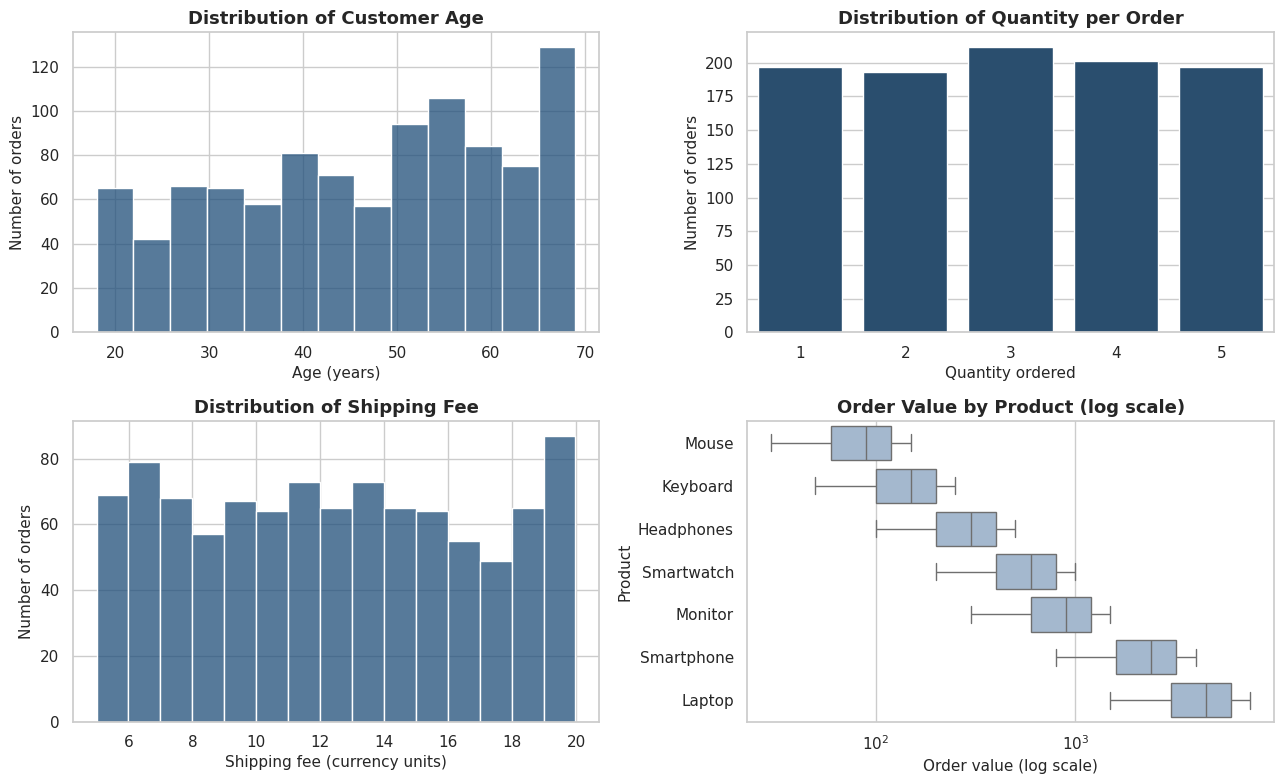

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(df["age"].dropna(), bins=13, color=MAIN, ax=axes[0, 0])
axes[0, 0].set(title="Distribution of Customer Age", xlabel="Age (years)", ylabel="Number of orders")

sns.countplot(x="quantity", data=df, color=MAIN, ax=axes[0, 1])
axes[0, 1].set(title="Distribution of Quantity per Order", xlabel="Quantity ordered", ylabel="Number of orders")

sns.histplot(df["shipping_fee"], bins=15, color=MAIN, ax=axes[1, 0])
axes[1, 0].set(title="Distribution of Shipping Fee", xlabel="Shipping fee (currency units)", ylabel="Number of orders")

order_prod = df.groupby("product_name")["total_price"].median().sort_values().index
sns.boxplot(x="total_price", y="product_name", data=df, order=order_prod, color="#9DB7D5", ax=axes[1, 1])
axes[1, 1].set_xscale("log")
axes[1, 1].set(title="Order Value by Product (log scale)", xlabel="Order value (log scale)", ylabel="Product")
save_fig("01_eda_distributions")
plt.show()

In [ ]:
print("Order value is strongly right-skewed because product prices range from 30 to 1,500 per unit:")
print(f"  mean order value = {df['total_price'].mean():,.0f}, median = {df['total_price'].median():,.0f}, skewness = {df['total_price'].skew():.2f}")
print("Quantity is almost evenly spread across 1-5 and shipping fee is evenly spread between about 5 and 20.")
print("Customers by number of orders:")
display(df.groupby("customer_id").size().value_counts().sort_index().rename_axis("orders per customer").to_frame("customers").T)

Order value is strongly right-skewed because product prices range from 30 to 1,500 per unit:
  mean order value = 1,347, median = 600, skewness = 1.93
Quantity is almost evenly spread across 1-5 and shipping fee is evenly spread between about 5 and 20.
Customers by number of orders:


orders per customer,1,2,3,4,5,6,7,8,9
customers,41,61,60,56,39,18,10,3,4


## 12. KPI Analysis
KPI formulas, based on the real columns:

* **Total Revenue** = Σ `total_price`  |  **Total Orders** = number of rows (each row is one order)
* **Average Order Value (AOV)** = Total Revenue ÷ Total Orders
* **Return Rate** = Returned Orders ÷ Orders with a recorded shipping status × 100
* **Net Revenue** = revenue from orders that were not returned

In [ ]:
rec = int(df["status_recorded"].sum())
kpi = {
    "total_revenue": df["total_price"].sum(),
    "total_orders": len(df),
    "total_quantity": int(df["quantity"].sum()),
    "avg_order_value": df["total_price"].sum() / len(df),
    "avg_unit_price_per_order": df["unit_price"].mean(),
    "avg_list_price_of_products": df.groupby("product_name")["unit_price"].first().mean(),
    "customers": df["customer_id"].nunique(),
    "products": df["product_name"].nunique(),
    "categories": df["category"].nunique(),
    "delivered": int(df["is_delivered"].sum()),
    "in_transit": int(df["is_in_transit"].sum()),
    "returned": int(df["is_returned"].sum()),
    "unknown_status": int((df["shipping_status"] == "Unknown").sum()),
    "return_rate": df["is_returned"].sum() / rec * 100,
    "return_rate_all_orders": df["is_returned"].sum() / len(df) * 100,
    "returned_revenue": df.loc[df["is_returned"] == 1, "total_price"].sum(),
    "net_revenue": df["net_revenue"].sum(),
    "avg_shipping_fee": df["shipping_fee"].mean(),
}
kpi["returned_revenue_pct"] = kpi["returned_revenue"] / kpi["total_revenue"] * 100

kpi_table = pd.DataFrame([
    ("Total Revenue (gross sales)", f"{kpi['total_revenue']:,.0f}"),
    ("Net Revenue (excluding returned orders)", f"{kpi['net_revenue']:,.0f}"),
    ("Revenue in Returned Orders", f"{kpi['returned_revenue']:,.0f}  ({kpi['returned_revenue_pct']:.1f}% of revenue)"),
    ("Total Orders", f"{kpi['total_orders']:,}"),
    ("Total Quantity Sold", f"{kpi['total_quantity']:,}"),
    ("Average Order Value", f"{kpi['avg_order_value']:,.2f}"),
    ("Average Unit Price (per order)", f"{kpi['avg_unit_price_per_order']:,.2f}"),
    ("Average Product List Price (7 products)", f"{kpi['avg_list_price_of_products']:,.2f}"),
    ("Average Shipping Fee", f"{kpi['avg_shipping_fee']:,.2f}"),
    ("Number of Customers", f"{kpi['customers']}"),
    ("Number of Products", f"{kpi['products']}"),
    ("Number of Categories", f"{kpi['categories']}"),
    ("Delivered Orders", f"{kpi['delivered']}"),
    ("In Transit Orders", f"{kpi['in_transit']}"),
    ("Returned Orders", f"{kpi['returned']}"),
    ("Orders with Unknown Status", f"{kpi['unknown_status']}"),
    ("Overall Return Rate (of recorded-status orders)", f"{kpi['return_rate']:.2f}%"),
    ("Return Rate (of all orders, for reference)", f"{kpi['return_rate_all_orders']:.2f}%"),
], columns=["KPI", "Value"]).set_index("KPI")
kpi_table

,Value
KPI,
Total Revenue (gross sales),"1,346,600"
Net Revenue (excluding returned orders),"930,960"
Revenue in Returned Orders,"415,640 (30.9% of revenue)"
Total Orders,"1,000"
Total Quantity Sold,"3,008"
Average Order Value,"1,346.60"
Average Unit Price (per order),446.63
Average Product List Price (7 products),425.71
Average Shipping Fee,12.42


## 13. Product Analysis  *(Q1 and Q3)*
The catalogue contains only **7 products**, so a "Top 10" list is simply all 7 products ranked. The lowest-ranked product(s) act as the bottom performers.

,unit_price,revenue,revenue_share_%,orders,quantity,quantity_share_%,avg_order_value
product_name,,,,,,,
Laptop,"1,500.00",696000,51.69,154,464,15.43,"4,519.48"
Smartphone,800.00,353600,26.26,142,442,14.69,"2,490.14"
Monitor,300.00,150900,11.21,181,503,16.72,833.70
Smartwatch,200.00,74200,5.51,122,371,12.33,608.20
Headphones,100.00,37000,2.75,120,370,12.30,308.33
Keyboard,50.00,22900,1.70,145,458,15.23,157.93
Mouse,30.00,12000,0.89,136,400,13.30,88.24


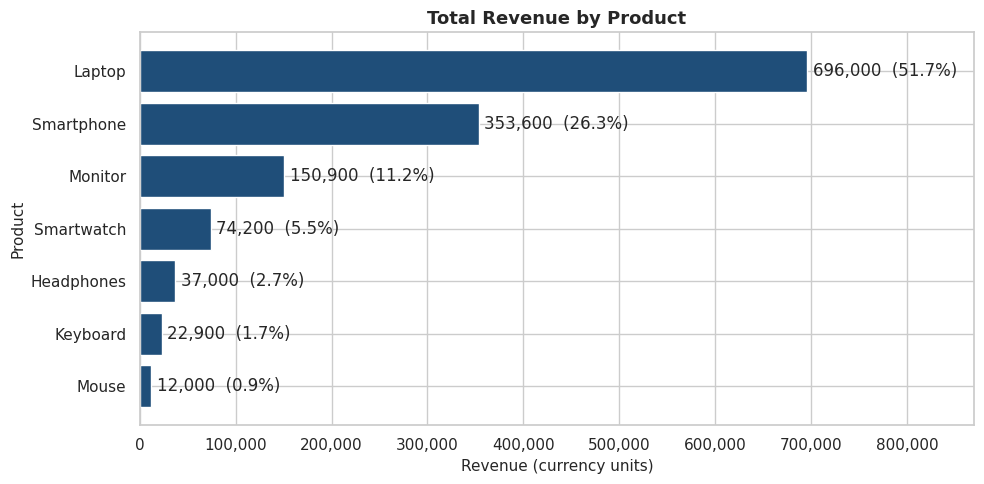

In [ ]:
prod = summarise(df, "product_name").sort_values("revenue", ascending=False)
prod["quantity_share_%"] = prod["quantity"] / prod["quantity"].sum() * 100
prod["unit_price"] = df.groupby("product_name")["unit_price"].first()
display(prod[["unit_price", "revenue", "revenue_share_%", "orders", "quantity", "quantity_share_%", "avg_order_value"]])

fig, ax = plt.subplots(figsize=(10, 5))
d = prod.sort_values("revenue")
bars = ax.barh(d.index, d["revenue"], color=MAIN)
ax.bar_label(bars, labels=[f"{v:,.0f}  ({s:.1f}%)" for v, s in zip(d["revenue"], d["revenue_share_%"])], padding=4)
ax.set(title="Total Revenue by Product", xlabel="Revenue (currency units)", ylabel="Product")
ax.set_xlim(0, d["revenue"].max() * 1.25)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
save_fig("02_revenue_by_product")
plt.show()

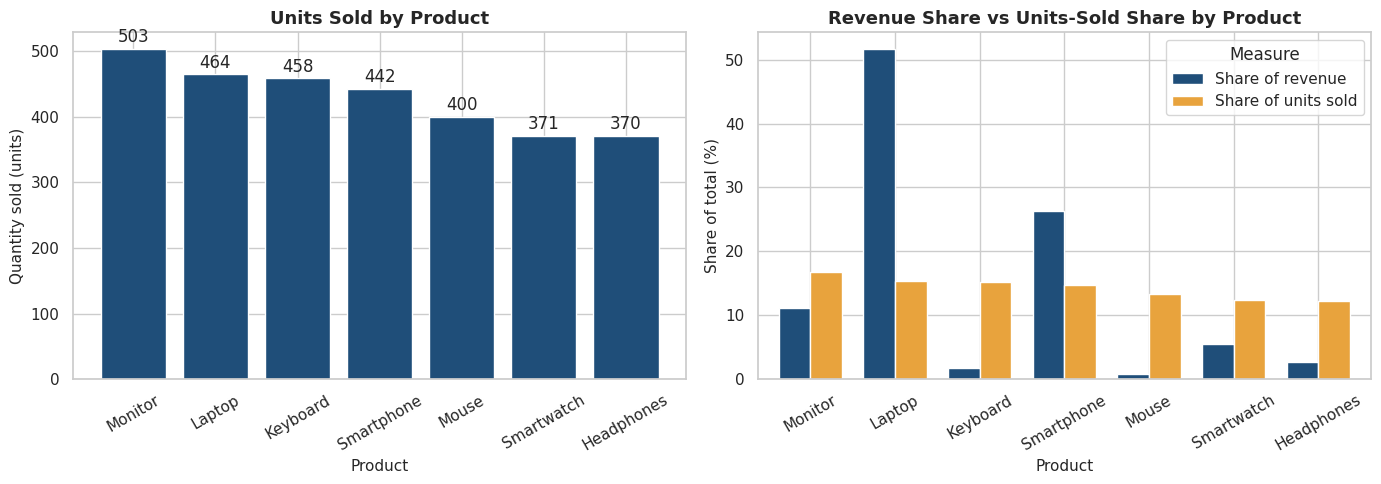

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d = prod.sort_values("quantity", ascending=False)
bars = axes[0].bar(d.index, d["quantity"], color=MAIN)
axes[0].bar_label(bars, padding=2)
axes[0].set(title="Units Sold by Product", xlabel="Product", ylabel="Quantity sold (units)")
axes[0].tick_params(axis="x", rotation=30)

share = prod[["revenue_share_%", "quantity_share_%"]].loc[d.index]
share.columns = ["Share of revenue", "Share of units sold"]
share.plot(kind="bar", ax=axes[1], color=[MAIN, "#E8A33D"], width=0.75)
axes[1].set(title="Revenue Share vs Units-Sold Share by Product", xlabel="Product", ylabel="Share of total (%)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(title="Measure")
save_fig("03_quantity_vs_revenue_by_product")
plt.show()

In [ ]:
top_rev, low_rev = prod.index[0], prod.index[-1]
top_qty = prod["quantity"].idxmax()
display(Markdown(f"""
**Insights – products**
* **{top_rev}** is the top revenue product: **{prod.loc[top_rev,'revenue']:,.0f}** ({prod.loc[top_rev,'revenue_share_%']:.1f}% of revenue) from only {prod.loc[top_rev,'orders']} orders ({prod.loc[top_rev,'orders']/len(df)*100:.1f}% of orders).
* The top two products ({prod.index[0]} and {prod.index[1]}) together generate **{prod['revenue_share_%'].iloc[:2].sum():.1f}%** of revenue.
* **{top_qty}** sold the most units (**{prod.loc[top_qty,'quantity']}**), but gives only {prod.loc[top_qty,'revenue_share_%']:.1f}% of revenue – high volume does not mean high revenue.
* The weakest revenue product is **{low_rev}** ({prod.loc[low_rev,'revenue']:,.0f}, {prod.loc[low_rev,'revenue_share_%']:.1f}% of revenue) even though it sold {prod.loc[low_rev,'quantity']} units.
* Units sold are spread fairly evenly ({prod['quantity'].min()} to {prod['quantity'].max()} units per product); price, not volume, explains the revenue differences.
"""))


**Insights – products**
* **Laptop** is the top revenue product: **696,000** (51.7% of revenue) from only 154 orders (15.4% of orders).
* The top two products (Laptop and Smartphone) together generate **77.9%** of revenue.
* **Monitor** sold the most units (**503**), but gives only 11.2% of revenue – high volume does not mean high revenue.
* The weakest revenue product is **Mouse** (12,000, 0.9% of revenue) even though it sold 400 units.
* Units sold are spread fairly evenly (370 to 503 units per product); price, not volume, explains the revenue differences.


## 14. Category Analysis  *(Q1 and Q9 – category part)*

,products,revenue,revenue_share_%,orders,quantity,avg_order_value,return_rate_%
category,,,,,,,
Electronics,3,1200500,89.15,477,1409,"2,516.77",31.85
Wearables,1,74200,5.51,122,371,608.20,32.48
Accessories,3,71900,5.34,401,1228,179.30,33.07


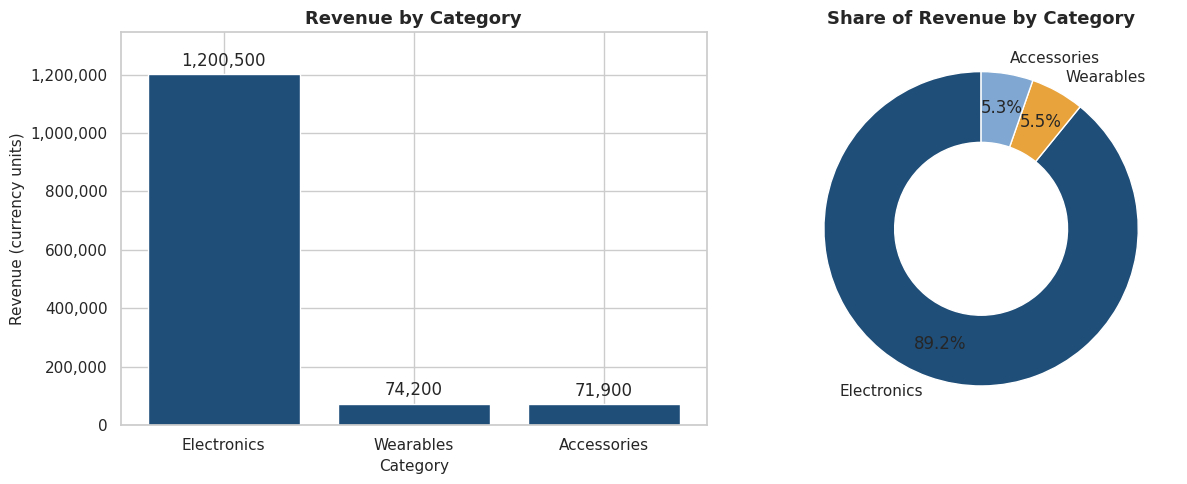

In [ ]:
cat = summarise(df, "category").sort_values("revenue", ascending=False)
cat["products"] = df.groupby("category")["product_name"].nunique()
display(cat[["products", "revenue", "revenue_share_%", "orders", "quantity", "avg_order_value", "return_rate_%"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bars = axes[0].bar(cat.index, cat["revenue"], color=MAIN)
axes[0].bar_label(bars, labels=[f"{v:,.0f}" for v in cat["revenue"]], padding=3)
axes[0].set(title="Revenue by Category", xlabel="Category", ylabel="Revenue (currency units)")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].set_ylim(0, cat["revenue"].max() * 1.12)

axes[1].pie(cat["revenue"], labels=cat.index, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
            colors=[MAIN, "#E8A33D", "#7FA7D1"], wedgeprops=dict(width=0.45, edgecolor="white"))
axes[1].set_title("Share of Revenue by Category")
save_fig("04_revenue_by_category")
plt.show()

In [ ]:
best_cat = cat.index[0]
acc = cat.loc["Accessories"]
display(Markdown(f"""
**Insights – categories**
* **{best_cat}** is the best category: **{cat.loc[best_cat,'revenue']:,.0f}** = **{cat.loc[best_cat,'revenue_share_%']:.1f}%** of revenue from {cat.loc[best_cat,'orders']} orders.
* **Accessories** have a large order share ({acc['orders']/len(df)*100:.1f}% of orders, {int(acc['quantity']):,} units) but contribute only **{acc['revenue_share_%']:.1f}%** of revenue because their average order value is just {acc['avg_order_value']:,.0f}.
* Revenue is therefore highly concentrated in a single category.
"""))


**Insights – categories**
* **Electronics** is the best category: **1,200,500** = **89.2%** of revenue from 477 orders.
* **Accessories** have a large order share (40.1% of orders, 1,228 units) but contribute only **5.3%** of revenue because their average order value is just 179.
* Revenue is therefore highly concentrated in a single category.


## 15. Regional Analysis  *(Q2, Q9)*
Orders with an **Unknown** region (missing in the raw data) are shown in the table for completeness but are **excluded from the strongest/weakest ranking**.

,revenue,revenue_share_%,orders,quantity,avg_order_value
region,,,,,
East,329950,24.50,231,715,"1,428.35"
North,324990,24.13,229,702,"1,419.17"
West,323390,24.02,246,733,"1,314.59"
South,301040,22.36,244,726,"1,233.77"
Unknown,67230,4.99,50,132,"1,344.60"


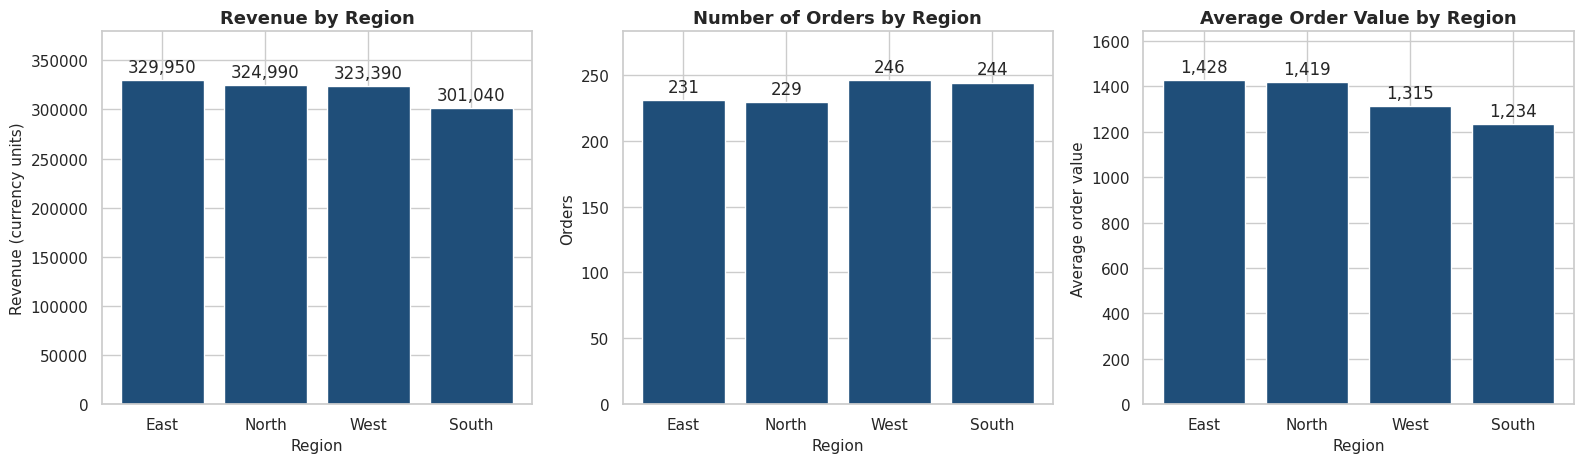

In [ ]:
reg_all = summarise(df, "region")
reg = reg_all.loc[REGION_ORDER].sort_values("revenue", ascending=False)
display(reg_all.loc[list(reg.index) + ["Unknown"], ["revenue", "revenue_share_%", "orders", "quantity", "avg_order_value"]])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (col, title, ylabel) in zip(axes, [("revenue", "Revenue by Region", "Revenue (currency units)"),
                                          ("orders", "Number of Orders by Region", "Orders"),
                                          ("avg_order_value", "Average Order Value by Region", "Average order value")]):
    bars = ax.bar(reg.index, reg[col], color=MAIN)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in reg[col]], padding=3)
    ax.set(title=title, xlabel="Region", ylabel=ylabel)
    ax.set_ylim(0, reg[col].max() * 1.15)
save_fig("05_regional_performance")
plt.show()

In [ ]:
r_top, r_low = reg.index[0], reg.index[-1]
gap = (reg.loc[r_top, "revenue"] / reg.loc[r_low, "revenue"] - 1) * 100
display(Markdown(f"""
**Insights – regions** (recorded regions only)
* **Strongest region: {r_top}** – revenue {reg.loc[r_top,'revenue']:,.0f} ({reg.loc[r_top,'revenue_share_%']:.1f}% of total) and the highest average order value ({reg.loc[r_top,'avg_order_value']:,.0f}).
* **Weakest region: {r_low}** – revenue {reg.loc[r_low,'revenue']:,.0f} ({reg.loc[r_low,'revenue_share_%']:.1f}%). The gap between best and weakest is {gap:.1f}%, so regional revenue is fairly balanced.
* Most orders: **{reg['orders'].idxmax()}** ({reg['orders'].max()} orders), but its revenue ranks {list(reg.index).index(reg['orders'].idxmax())+1} of 4, because its average order value ({reg.loc[reg['orders'].idxmax(),'avg_order_value']:,.0f}) is lower than that of {reg['avg_order_value'].idxmax()} ({reg['avg_order_value'].max():,.0f}).
* {reg_all.loc['Unknown','orders']} orders ({reg_all.loc['Unknown','revenue']:,.0f} revenue) have no region recorded – improving region capture is a data-quality action.
"""))


**Insights – regions** (recorded regions only)
* **Strongest region: East** – revenue 329,950 (24.5% of total) and the highest average order value (1,428).
* **Weakest region: South** – revenue 301,040 (22.4%). The gap between best and weakest is 9.6%, so regional revenue is fairly balanced.
* Most orders: **West** (246 orders), but its revenue ranks 3 of 4, because its average order value (1,315) is lower than that of East (1,428).
* 50 orders (67,230 revenue) have no region recorded – improving region capture is a data-quality action.


### Category × Region revenue  *(Q9)*

region,East,North,South,West,Unknown,Total
category,,,,,,
Electronics,288900,294500,266600,289700,60800,1200500
Wearables,23800,14000,17800,15200,3400,74200
Accessories,17250,16490,16640,18490,3030,71900
Total,329950,324990,301040,323390,67230,1346600


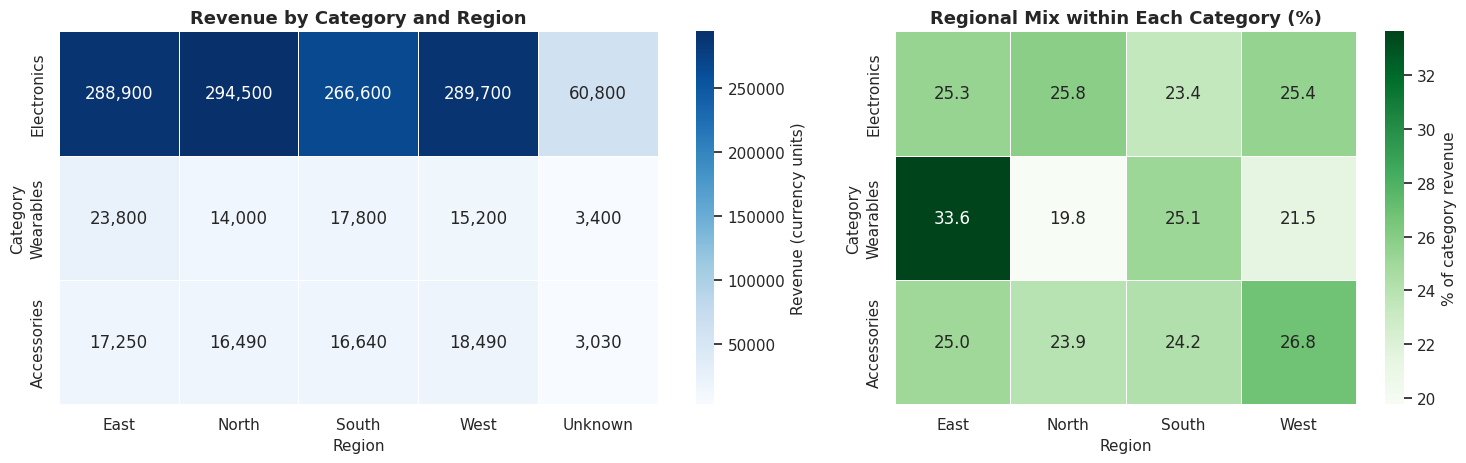

In [ ]:
cr = df.pivot_table(index="category", columns="region", values="total_price", aggfunc="sum", fill_value=0)
cr = cr[REGION_ORDER + ["Unknown"]].loc[cat.index]
cr["Total"] = cr.sum(axis=1)
cr.loc["Total"] = cr.sum()
display(cr)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(cr.drop(index="Total", columns="Total"), annot=True, fmt=",.0f", cmap="Blues", linewidths=.5,
            cbar_kws={"label": "Revenue (currency units)"}, ax=axes[0])
axes[0].set(title="Revenue by Category and Region", xlabel="Region", ylabel="Category")

share = cr.drop(index="Total", columns=["Total", "Unknown"])
share = share.div(share.sum(axis=1), axis=0) * 100
sns.heatmap(share, annot=True, fmt=".1f", cmap="Greens", linewidths=.5, cbar_kws={"label": "% of category revenue"}, ax=axes[1])
axes[1].set(title="Regional Mix within Each Category (%)", xlabel="Region", ylabel="Category")
save_fig("06_category_region_heatmap")
plt.show()

In [ ]:
wr = cr.loc["Wearables", REGION_ORDER]
el_share = cr.loc["Electronics", REGION_ORDER] / cr.loc["Total", REGION_ORDER] * 100   # Electronics share of each region's revenue
display(Markdown(f"""
**Insights – category × region**
* **Electronics dominates every region**: it makes up {el_share.min():.0f}% to {el_share.max():.0f}% of each region's revenue.
* Highest single cell: **{cr.drop(index='Total',columns=['Total','Unknown']).stack().idxmax()}** = {cr.drop(index='Total',columns=['Total','Unknown']).stack().max():,.0f}.
* Wearables vary the most by region: best in **{wr.idxmax()}** ({wr.max():,.0f}) and lowest in **{wr.idxmin()}** ({wr.min():,.0f}).
"""))


**Insights – category × region**
* **Electronics dominates every region**: it makes up 88% to 91% of each region's revenue.
* Highest single cell: **('Electronics', 'North')** = 294,500.
* Wearables vary the most by region: best in **East** (23,800) and lowest in **North** (14,000).


## 16. Monthly Sales Analysis  *(Q4)*
The data covers all of 2023 plus **only the first 3 days of January 2024**. That last month is incomplete, so it is shown on the charts but **not used for "highest/lowest month" or month-over-month comparisons**.

In [ ]:
mon = df.groupby("order_month").agg(revenue=("total_price", "sum"), orders=("total_price", "size"),
                                    quantity=("quantity", "sum"), full_month=("full_month", "first"))
mon["avg_order_value"] = mon["revenue"] / mon["orders"]
mon["revenue_MoM_%"] = mon["revenue"].pct_change() * 100
mon["orders_MoM_%"] = mon["orders"].pct_change() * 100
mon.loc[~mon["full_month"], ["revenue_MoM_%", "orders_MoM_%"]] = np.nan      # partial month is not comparable
mon.index = mon.index.strftime("%b %Y")
display(mon)

full = mon[mon["full_month"]]
print(f"Highest revenue month : {full['revenue'].idxmax()}  ({full['revenue'].max():,.0f})")
print(f"Lowest revenue month  : {full['revenue'].idxmin()}  ({full['revenue'].min():,.0f})")
print(f"Highest order month   : {full['orders'].idxmax()}  ({full['orders'].max()})")
print(f"Lowest order month    : {full['orders'].idxmin()}  ({full['orders'].min()})")

Highest revenue month : Nov 2023  (147,150)
Lowest revenue month  : Mar 2023  (67,660)
Highest order month   : Jan 2023  (94)
Lowest order month    : Apr 2023  (66)


,revenue,orders,quantity,full_month,avg_order_value,revenue_MoM_%,orders_MoM_%
order_month,,,,,,,
Jan 2023,141360,94,298,True,"1,503.83",NaN,NaN
Feb 2023,78910,74,201,True,"1,066.35",-44.18,-21.28
Mar 2023,67660,67,210,True,"1,009.85",-14.26,-9.46
Apr 2023,87840,66,189,True,"1,330.91",29.83,-1.49
May 2023,120080,86,267,True,"1,396.28",36.70,30.30
Jun 2023,129450,90,274,True,"1,438.33",7.80,4.65
Jul 2023,103160,79,226,True,"1,305.82",-20.31,-12.22
Aug 2023,108050,84,239,True,"1,286.31",4.74,6.33
Sep 2023,119490,81,240,True,"1,475.19",10.59,-3.57


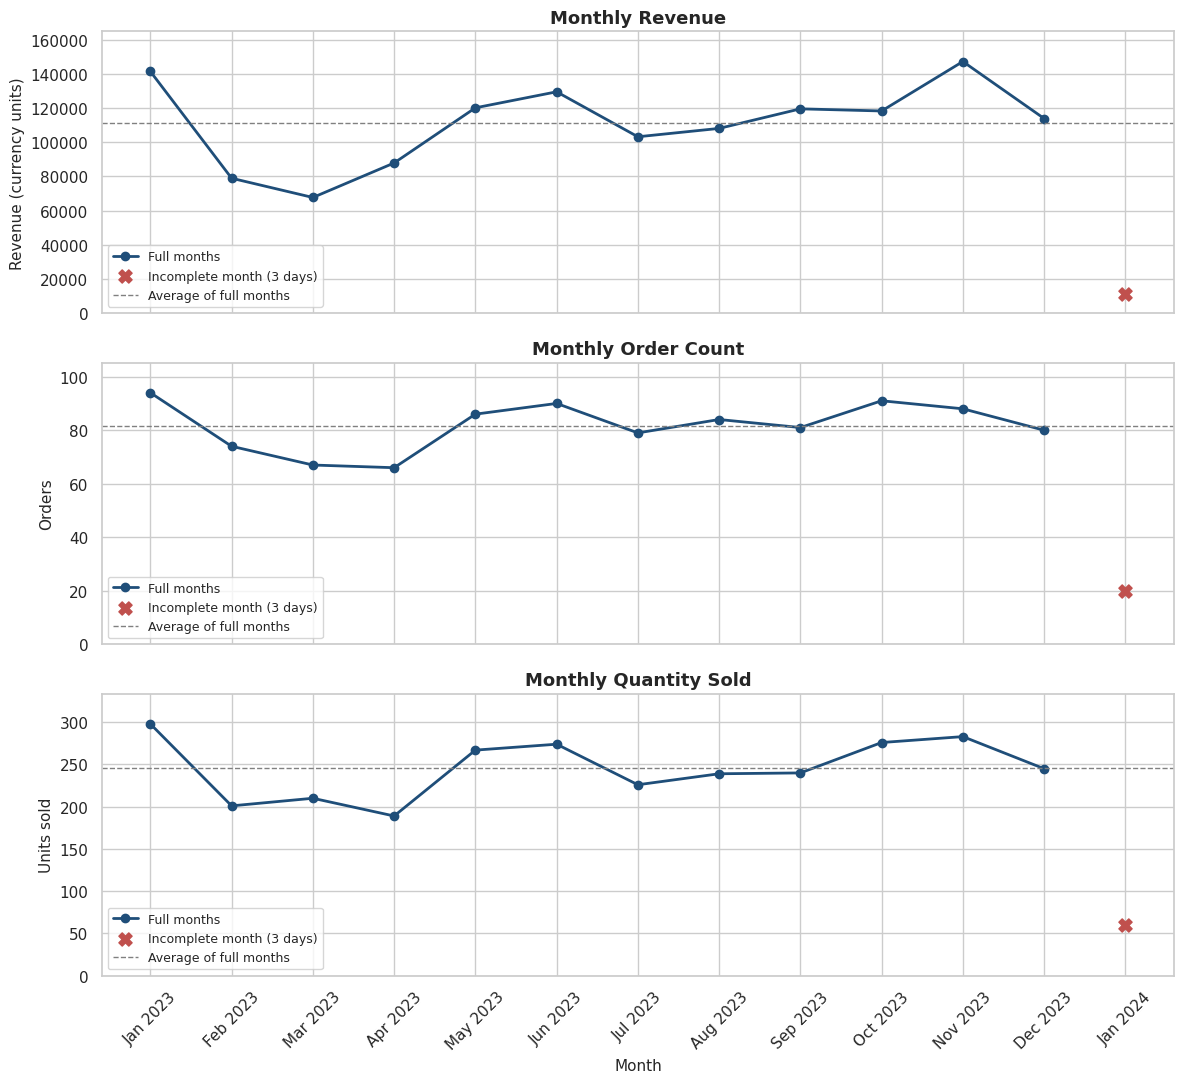

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
for ax, (col, title, ylabel) in zip(axes, [("revenue", "Monthly Revenue", "Revenue (currency units)"),
                                          ("orders", "Monthly Order Count", "Orders"),
                                          ("quantity", "Monthly Quantity Sold", "Units sold")]):
    ax.plot(full.index, full[col], marker="o", color=MAIN, linewidth=2, label="Full months")
    part = mon[~mon["full_month"]]
    ax.scatter(part.index, part[col], marker="X", s=90, color=ACCENT, zorder=5, label="Incomplete month (3 days)")
    ax.axhline(full[col].mean(), color="grey", linestyle="--", linewidth=1, label="Average of full months")
    ax.set(title=title, ylabel=ylabel)
    ax.set_ylim(0, full[col].max() * 1.12)
    ax.legend(loc="lower left", fontsize=9)
axes[-1].set_xlabel("Month")
plt.setp(axes[-1].get_xticklabels(), rotation=45)
save_fig("07_monthly_trends")
plt.show()

In [ ]:
first, lastf = full.index[0], full.index[-1]
up = full["revenue_MoM_%"].idxmax(); dn = full["revenue_MoM_%"].idxmin()
display(Markdown(f"""
**Insights – monthly sales**
* **Peak month: {full['revenue'].idxmax()}** (revenue {full['revenue'].max():,.0f}); **weakest month: {full['revenue'].idxmin()}** ({full['revenue'].min():,.0f}) – the peak is {full['revenue'].max()/full['revenue'].min():.1f}× the weakest month.
* Largest month-over-month rise: **{up}** ({full.loc[up,'revenue_MoM_%']:+.1f}%); largest fall: **{dn}** ({full.loc[dn,'revenue_MoM_%']:+.1f}%).
* Revenue is not steady: it fell from {full.loc[first,'revenue']:,.0f} in {first} to a low in {full['revenue'].idxmin()}, recovered in the middle of the year, and was {full.loc[lastf,'revenue']:,.0f} in {lastf}.
* Average full-month revenue is {full['revenue'].mean():,.0f} from {full['orders'].mean():.0f} orders per month.
* Revenue and order count move closely together (correlation across months = {full['revenue'].corr(full['orders']):.2f}), although revenue is also affected by how many high-priced Laptops / Smartphones are sold in a month.
"""))


**Insights – monthly sales**
* **Peak month: Nov 2023** (revenue 147,150); **weakest month: Mar 2023** (67,660) – the peak is 2.2× the weakest month.
* Largest month-over-month rise: **May 2023** (+36.7%); largest fall: **Feb 2023** (-44.2%).
* Revenue is not steady: it fell from 141,360 in Jan 2023 to a low in Mar 2023, recovered in the middle of the year, and was 113,830 in Dec 2023.
* Average full-month revenue is 111,268 from 82 orders per month.
* Revenue and order count move closely together (correlation across months = 0.89), although revenue is also affected by how many high-priced Laptops / Smartphones are sold in a month.


## 17. Customer Analysis
Customer analysis uses `customer_id` only (gender/region are not stable per customer – see Section 8.10).

Customers: 292   Repeat customers (2+ orders): 251 (86.0%)


,count,mean,std,min,25%,50%,75%,max
revenue,292.00,"4,611.64","4,270.68",60.00,"1,295.00","3,595.00","6,592.50","29,100.00"
orders,292.00,3.42,1.78,1.00,2.00,3.00,5.00,9.00
quantity,292.00,10.30,5.87,1.00,6.00,9.00,14.00,34.00
avg_order_value,292.00,"1,306.45","1,107.48",30.00,515.50,945.71,"1,822.14","6,000.00"


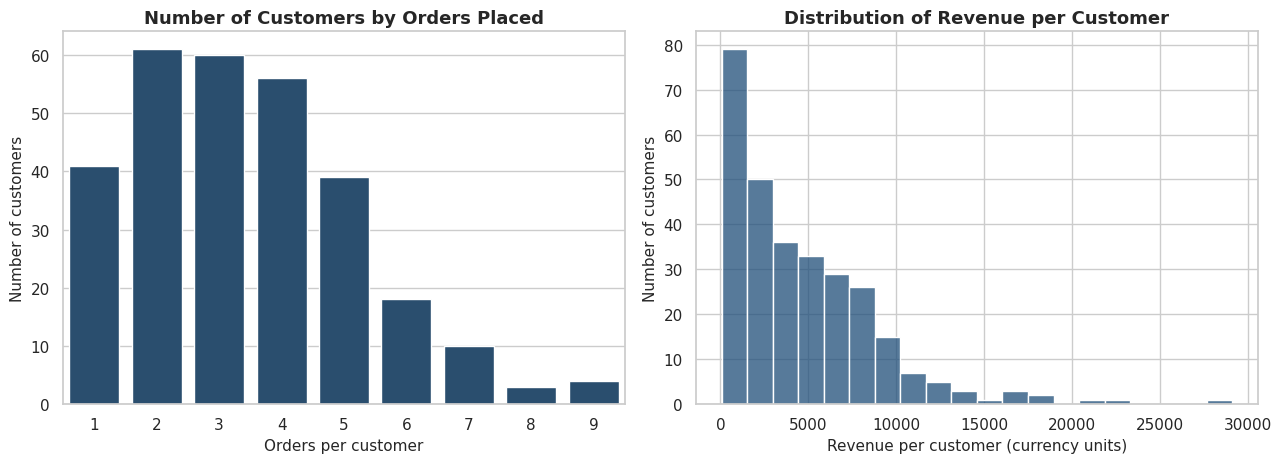

In [ ]:
cust = df.groupby("customer_id").agg(revenue=("total_price", "sum"), orders=("total_price", "size"),
                                      quantity=("quantity", "sum"), returned_orders=("is_returned", "sum"),
                                      recorded=("status_recorded", "sum"),
                                      first_order=("order_date", "min"), last_order=("order_date", "max"))
cust["avg_order_value"] = cust["revenue"] / cust["orders"]
cust["return_rate_%"] = np.where(cust["recorded"] > 0, cust["returned_orders"] / cust["recorded"].replace(0, np.nan) * 100, np.nan)
cust = cust.sort_values("revenue", ascending=False)

repeat = (cust["orders"] > 1).mean() * 100
display(cust[["revenue", "orders", "quantity", "avg_order_value"]].describe().T)
print(f"Customers: {len(cust)}   Repeat customers (2+ orders): {(cust['orders']>1).sum()} ({repeat:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.countplot(x="orders", data=cust, color=MAIN, ax=axes[0])
axes[0].set(title="Number of Customers by Orders Placed", xlabel="Orders per customer", ylabel="Number of customers")
sns.histplot(cust["revenue"], bins=20, color=MAIN, ax=axes[1])
axes[1].set(title="Distribution of Revenue per Customer", xlabel="Revenue per customer (currency units)", ylabel="Number of customers")
save_fig("08_customer_distributions")
plt.show()

## 18. Age Group Analysis  *(Q5)*
Customers are 18–69 years old (nobody is under 18), so five groups are used: 18–25, 26–35, 36–45, 46–55, 56+. Orders where no age exists for the customer are shown as *Unknown*.

,customers,revenue,revenue_share_%,orders,quantity,avg_order_value,revenue_per_customer
age_group,,,,,,,
18-25,37,126580,9.40,107,322,"1,182.99","3,421.08"
26-35,46,180780,13.42,150,430,"1,205.20","3,930.00"
36-45,56,246840,18.33,191,575,"1,292.36","4,407.86"
46-55,54,295370,21.93,206,641,"1,433.83","5,469.81"
56+,94,482370,35.82,339,1022,"1,422.92","5,131.60"
Unknown,5,14660,1.09,7,18,"2,094.29","2,932.00"


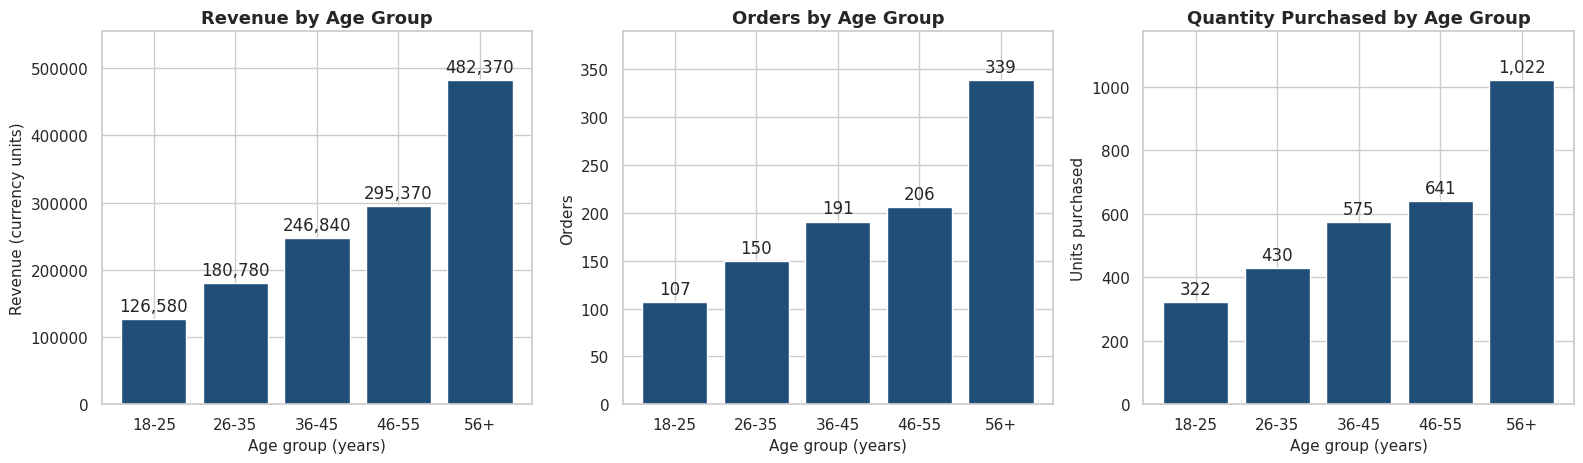

In [ ]:
age_t = summarise(df, "age_group")
age_t["customers"] = df.groupby("age_group")["customer_id"].nunique()
age_t["revenue_per_customer"] = age_t["revenue"] / age_t["customers"]
age_t = age_t.loc[AGE_ORDER + ["Unknown"]]
display(age_t[["customers", "revenue", "revenue_share_%", "orders", "quantity", "avg_order_value", "revenue_per_customer"]])

a = age_t.loc[AGE_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (col, title, yl) in zip(axes, [("revenue", "Revenue by Age Group", "Revenue (currency units)"),
                                      ("orders", "Orders by Age Group", "Orders"),
                                      ("quantity", "Quantity Purchased by Age Group", "Units purchased")]):
    bars = ax.bar(a.index, a[col], color=MAIN)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in a[col]], padding=3)
    ax.set(title=title, xlabel="Age group (years)", ylabel=yl)
    ax.set_ylim(0, a[col].max() * 1.15)
save_fig("09_age_group_analysis")
plt.show()

In [ ]:
ag_top = a["revenue"].idxmax(); ag_low = a["revenue"].idxmin()
display(Markdown(f"""
**Insights – age groups**
* The **{ag_top}** group is the largest: **{a.loc[ag_top,'revenue']:,.0f}** revenue (**{a.loc[ag_top,'revenue_share_%']:.1f}%**), {a.loc[ag_top,'orders']} orders and {a.loc[ag_top,'quantity']:,} units. The smallest is **{ag_low}** ({a.loc[ag_low,'revenue_share_%']:.1f}%).
* The two oldest groups (46-55 and 56+) together generate **{a.loc[['46-55','56+'],'revenue_share_%'].sum():.1f}%** of revenue.
* Part of this is simply group size: 56+ is a wide age band (56-69). Per customer, revenue is {a.loc['56+','revenue_per_customer']:,.0f} for 56+ versus {a.loc['18-25','revenue_per_customer']:,.0f} for 18-25.
* Average order value is similar across groups ({a['avg_order_value'].min():,.0f} to {a['avg_order_value'].max():,.0f}); the difference comes mainly from how many orders each group places.
"""))


**Insights – age groups**
* The **56+** group is the largest: **482,370** revenue (**35.8%**), 339 orders and 1,022 units. The smallest is **18-25** (9.4%).
* The two oldest groups (46-55 and 56+) together generate **57.8%** of revenue.
* Part of this is simply group size: 56+ is a wide age band (56-69). Per customer, revenue is 5,132 for 56+ versus 3,421 for 18-25.
* Average order value is similar across groups (1,183 to 1,434); the difference comes mainly from how many orders each group places.


## 19. Gender Analysis  *(Q5)*
Gender is analysed as recorded **on each order** (see the limitation in Section 8.10).

,revenue,revenue_share_%,orders,quantity,avg_order_value,return_rate_%
gender,,,,,,
Male,715590,53.14,524,1586,"1,365.63",34.55
Female,631010,46.86,476,1422,"1,325.65",30.11


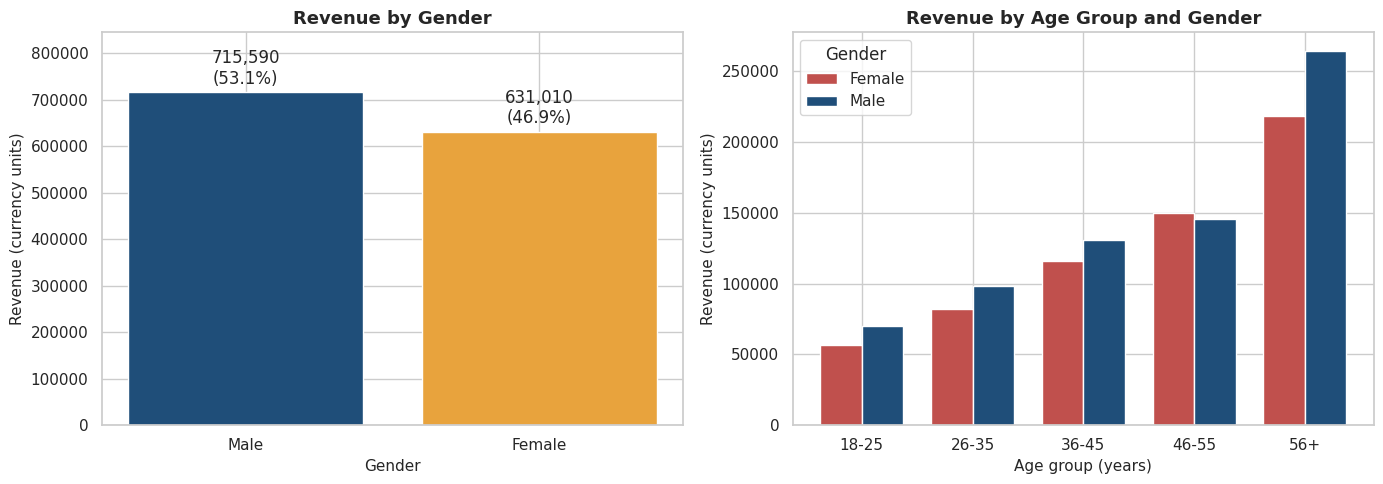

In [ ]:
gen = summarise(df, "gender").sort_values("revenue", ascending=False)
display(gen[["revenue", "revenue_share_%", "orders", "quantity", "avg_order_value", "return_rate_%"]])

ga = df.pivot_table(index="age_group", columns="gender", values="total_price", aggfunc="sum").loc[AGE_ORDER]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(gen.index, gen["revenue"], color=[MAIN, "#E8A33D"])
axes[0].bar_label(bars, labels=[f"{v:,.0f}\n({s:.1f}%)" for v, s in zip(gen["revenue"], gen["revenue_share_%"])], padding=3)
axes[0].set(title="Revenue by Gender", xlabel="Gender", ylabel="Revenue (currency units)")
axes[0].set_ylim(0, gen["revenue"].max() * 1.18)
ga.plot(kind="bar", ax=axes[1], color=[ACCENT, MAIN], width=0.75)
axes[1].set(title="Revenue by Age Group and Gender", xlabel="Age group (years)", ylabel="Revenue (currency units)")
axes[1].tick_params(axis="x", rotation=0); axes[1].legend(title="Gender")
save_fig("10_gender_analysis")
plt.show()

In [ ]:
gl, gs = gen.index[0], gen.index[1]
display(Markdown(f"""
**Insights – gender**
* **{gl}** orders generate {gen.loc[gl,'revenue']:,.0f} ({gen.loc[gl,'revenue_share_%']:.1f}%) versus {gen.loc[gs,'revenue']:,.0f} ({gen.loc[gs,'revenue_share_%']:.1f}%) for {gs}.
* The gap is small: orders are {gen.loc[gl,'orders']} vs {gen.loc[gs,'orders']} and average order value is {gen.loc[gl,'avg_order_value']:,.0f} vs {gen.loc[gs,'avg_order_value']:,.0f}. Both genders are important buyers.
* In the age-group chart the 56+ group is the largest for both genders, so age matters more than gender for revenue.
"""))


**Insights – gender**
* **Male** orders generate 715,590 (53.1%) versus 631,010 (46.9%) for Female.
* The gap is small: orders are 524 vs 476 and average order value is 1,366 vs 1,326. Both genders are important buyers.
* In the age-group chart the 56+ group is the largest for both genders, so age matters more than gender for revenue.


## 20. Shipping Status Analysis  *(Q7)*
Percentages are shown on **recorded-status orders** (so Delivered + In Transit + Returned = 100%); the table also shows the share of *all* orders including those with unknown status.

,orders,% of all orders,% of recorded-status orders,revenue,avg_shipping_fee
shipping_status,,,,,
Delivered,313,31.30,32.95,407380,12.39
In Transit,329,32.90,34.63,443560,12.85
Returned,308,30.80,32.42,415640,11.91
Unknown,50,5.00,NaN,80020,12.85


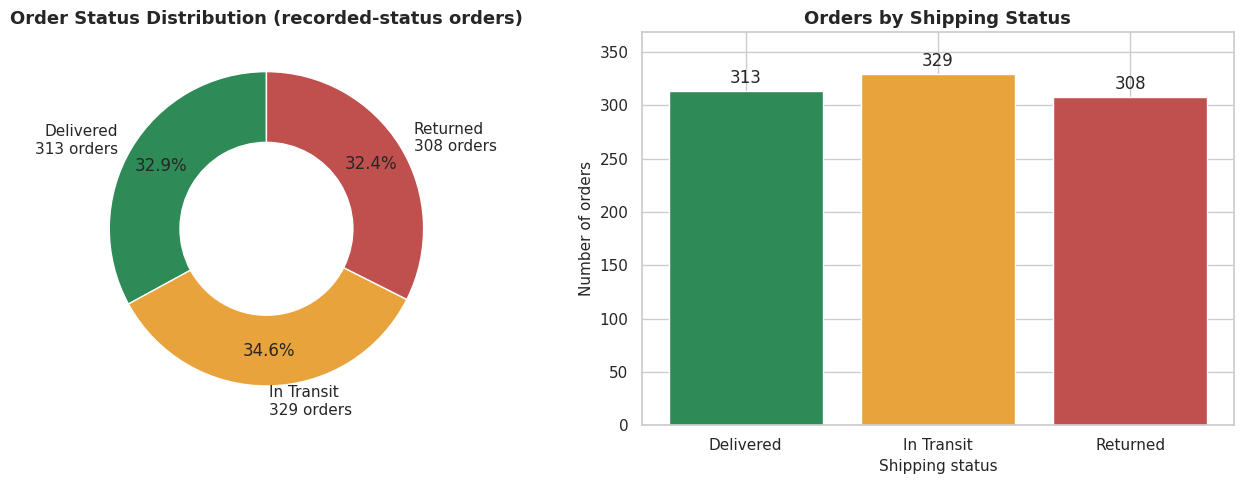

In [ ]:
ship = df["shipping_status"].value_counts().reindex(STATUS_ORDER + ["Unknown"]).to_frame("orders")
ship["% of all orders"] = ship["orders"] / len(df) * 100
ship["% of recorded-status orders"] = ship["orders"] / rec * 100
ship.loc["Unknown", "% of recorded-status orders"] = np.nan
ship["revenue"] = df.groupby("shipping_status")["total_price"].sum().reindex(ship.index)
ship["avg_shipping_fee"] = df.groupby("shipping_status")["shipping_fee"].mean().reindex(ship.index)
display(ship)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
vals = ship.loc[STATUS_ORDER, "orders"]
axes[0].pie(vals, labels=[f"{s}\n{n} orders" for s, n in vals.items()], autopct="%1.1f%%", startangle=90, pctdistance=0.78,
            colors=[STATUS_COLORS[s] for s in vals.index], wedgeprops=dict(width=0.45, edgecolor="white"))
axes[0].set_title("Order Status Distribution (recorded-status orders)")
bars = axes[1].bar(vals.index, vals.values, color=[STATUS_COLORS[s] for s in vals.index])
axes[1].bar_label(bars, padding=3)
axes[1].set(title="Orders by Shipping Status", xlabel="Shipping status", ylabel="Number of orders")
axes[1].set_ylim(0, vals.max() * 1.12)
save_fig("11_shipping_status")
plt.show()

,avg_order_value,avg_fee,fee_as_%_of_order_value
category,,,
Electronics,"2,516.77",12.62,0.50
Wearables,608.20,12.35,2.03
Accessories,179.30,12.20,6.80


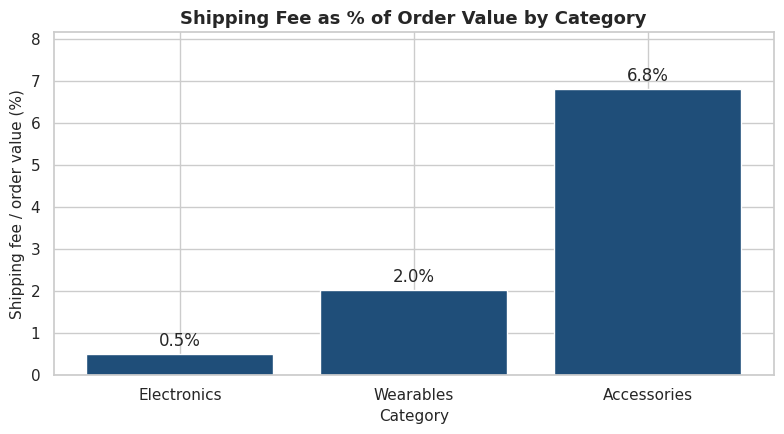

In [ ]:
# Shipping fee burden: fee as a % of order value (shipping cost matters most on low-priced orders)
fee = df.groupby("category").agg(avg_order_value=("total_price", "mean"), avg_fee=("shipping_fee", "mean"))
fee["fee_as_%_of_order_value"] = df.groupby("category").apply(lambda x: x["shipping_fee"].sum() / x["total_price"].sum() * 100)
fee = fee.loc[cat.index]
display(fee)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(fee.index, fee["fee_as_%_of_order_value"], color=MAIN)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in fee["fee_as_%_of_order_value"]], padding=3)
ax.set(title="Shipping Fee as % of Order Value by Category", xlabel="Category", ylabel="Shipping fee / order value (%)")
ax.set_ylim(0, fee["fee_as_%_of_order_value"].max() * 1.2)
save_fig("12_shipping_fee_burden")
plt.show()

In [ ]:
sp = ship.loc[STATUS_ORDER, "% of recorded-status orders"]
display(Markdown(f"""
**Insights – shipping status** (recorded-status orders, n = {rec})
* **Delivered: {sp['Delivered']:.1f}%** ({ship.loc['Delivered','orders']} orders)  |  **In Transit: {sp['In Transit']:.1f}%** ({ship.loc['In Transit','orders']})  |  **Returned: {sp['Returned']:.1f}%** ({ship.loc['Returned','orders']}).
* Only about **one in three orders is a confirmed delivery**, and almost **one in three is returned** – the three outcomes are nearly equal, which is a serious fulfilment concern.
* {ship.loc['Unknown','orders']} orders ({ship.loc['Unknown','% of all orders']:.1f}%) have no status; these should be closed in the order system.
* Shipping fee averages {kpi['avg_shipping_fee']:.2f} per order. It is only {fee.loc['Electronics','fee_as_%_of_order_value']:.1f}% of Electronics order value but **{fee.loc['Accessories','fee_as_%_of_order_value']:.1f}%** of Accessories order value, so low-priced orders carry a heavy shipping burden.
* Average shipping fee is almost the same for Delivered ({ship.loc['Delivered','avg_shipping_fee']:.2f}), In Transit ({ship.loc['In Transit','avg_shipping_fee']:.2f}) and Returned ({ship.loc['Returned','avg_shipping_fee']:.2f}) orders, so fee level does not appear to explain returns.
"""))


**Insights – shipping status** (recorded-status orders, n = 950)
* **Delivered: 32.9%** (313 orders)  |  **In Transit: 34.6%** (329)  |  **Returned: 32.4%** (308).
* Only about **one in three orders is a confirmed delivery**, and almost **one in three is returned** – the three outcomes are nearly equal, which is a serious fulfilment concern.
* 50 orders (5.0%) have no status; these should be closed in the order system.
* Shipping fee averages 12.42 per order. It is only 0.5% of Electronics order value but **6.8%** of Accessories order value, so low-priced orders carry a heavy shipping burden.
* Average shipping fee is almost the same for Delivered (12.39), In Transit (12.85) and Returned (11.91) orders, so fee level does not appear to explain returns.


## 21. Return Analysis  *(Q6 and Q8)*
**Return Rate = Returned Orders ÷ Orders with a recorded status × 100.**
Missing-status orders are excluded from the denominator because they cannot be classified as returned or not returned.

**Minimum-orders rule (Q8):** a return rate based on very few orders is unreliable, so products and regions are ranked only if they have **at least 30 recorded-status orders**. This is checked in the code below.

Unknown-region orders (not ranked): 22 returned of 49 recorded

Chi-square test (region vs returned): chi2 = 10.46, p-value = 0.0150  -> statistically significant difference


,orders,recorded_status,returned_orders,return_rate_%,returned_revenue,share_of_all_returns_%
region,,,,,,
West,246,238,95,39.92,108710,30.84
North,229,213,65,30.52,81170,21.10
East,231,217,62,28.57,101680,20.13
South,244,233,64,27.47,88900,20.78


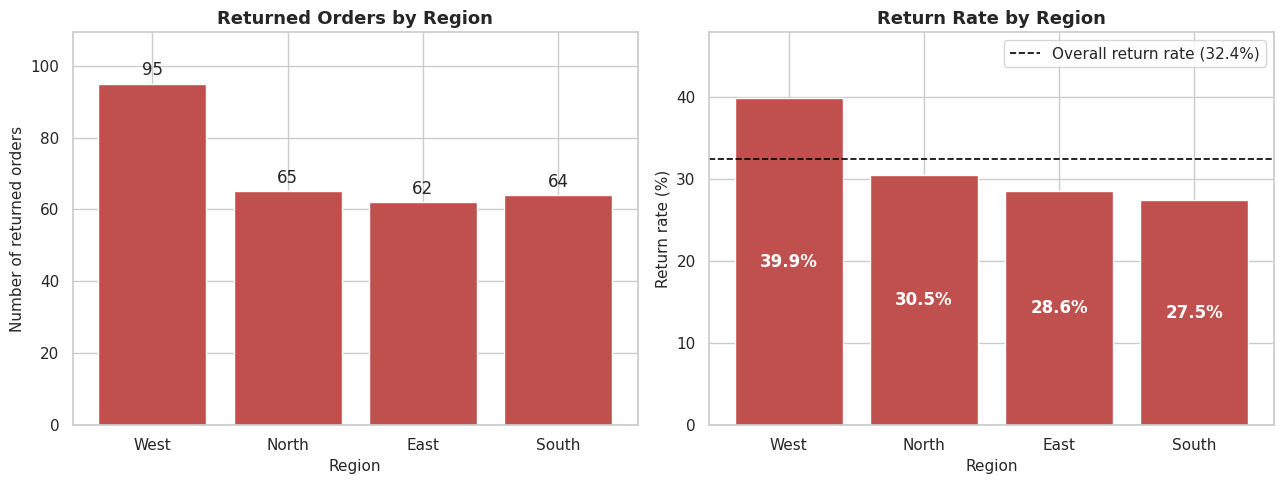

In [ ]:
MIN_ORDERS = 30
reg_ret = reg_all.loc[REGION_ORDER, ["orders", "recorded_status", "returned_orders", "return_rate_%"]].copy()
reg_ret["returned_revenue"] = df[df["is_returned"] == 1].groupby("region")["total_price"].sum().reindex(REGION_ORDER)
reg_ret["share_of_all_returns_%"] = reg_ret["returned_orders"] / df["is_returned"].sum() * 100
reg_ret = reg_ret.sort_values("return_rate_%", ascending=False)
display(reg_ret)
print("Unknown-region orders (not ranked):", int(reg_all.loc["Unknown", "returned_orders"]), "returned of",
      int(reg_all.loc["Unknown", "recorded_status"]), "recorded")

# statistical test: is the regional difference real or just chance?
kn = df[(df["status_recorded"] == 1) & (df["region"] != "Unknown")]
chi_reg = stats.chi2_contingency(pd.crosstab(kn["region"], kn["is_returned"]))
print(f"\nChi-square test (region vs returned): chi2 = {chi_reg[0]:.2f}, p-value = {chi_reg[1]:.4f}  ->",
      "statistically significant difference" if chi_reg[1] < 0.05 else "no significant difference")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bars = axes[0].bar(reg_ret.index, reg_ret["returned_orders"], color=ACCENT)
axes[0].bar_label(bars, padding=3)
axes[0].set(title="Returned Orders by Region", xlabel="Region", ylabel="Number of returned orders")
axes[0].set_ylim(0, reg_ret["returned_orders"].max() * 1.15)

bars = axes[1].bar(reg_ret.index, reg_ret["return_rate_%"], color=ACCENT)
axes[1].axhline(kpi["return_rate"], color="black", linestyle="--", linewidth=1.2, label=f"Overall return rate ({kpi['return_rate']:.1f}%)")
axes[1].bar_label(bars, labels=[f"{v:.1f}%" for v in reg_ret["return_rate_%"]], label_type="center", color="white", fontweight="bold")
axes[1].set(title="Return Rate by Region", xlabel="Region", ylabel="Return rate (%)")
axes[1].set_ylim(0, reg_ret["return_rate_%"].max() * 1.2); axes[1].legend()
save_fig("13_returns_by_region")
plt.show()

Products meeting the 30-order minimum: 7 of 7 (smallest product has 116 recorded orders)

Chi-square test (product vs returned): chi2 = 0.96, p-value = 0.9870  -> NOT statistically significant (differences are within normal random variation)


,orders,recorded_status,returned_orders,return_rate_%,revenue,returned_revenue
product_name,,,,,,
Headphones,120,116,40,34.48,37000,12000
Laptop,154,144,49,34.03,696000,223500
Mouse,136,131,44,33.59,12000,4140
Smartwatch,122,117,38,32.48,74200,22800
Smartphone,142,133,42,31.58,353600,102400
Keyboard,145,137,43,31.39,22900,7000
Monitor,181,172,52,30.23,150900,43800


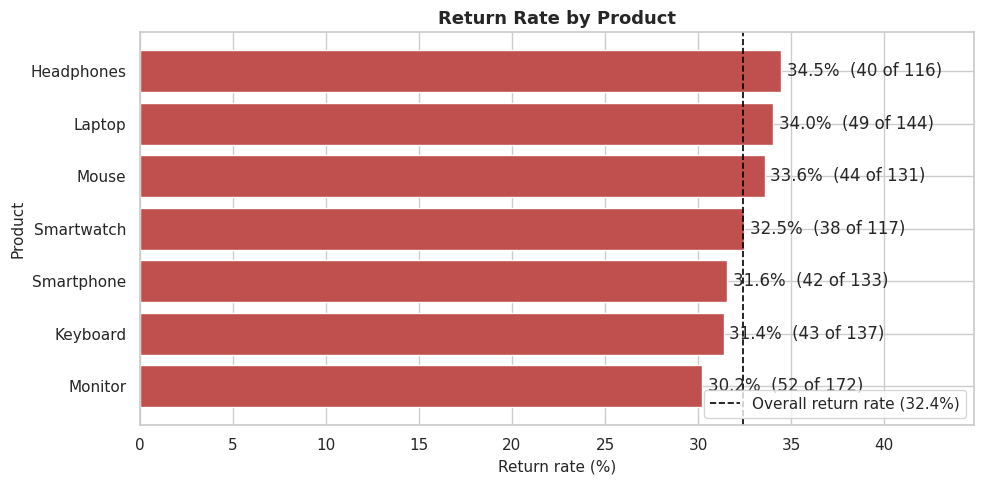

In [ ]:
# Return rate by product (minimum-orders rule applied)
prod_ret = prod[["orders", "recorded_status", "returned_orders", "return_rate_%", "revenue"]].copy()
prod_ret["returned_revenue"] = df[df["is_returned"] == 1].groupby("product_name")["total_price"].sum()
prod_ret["eligible"] = prod_ret["recorded_status"] >= MIN_ORDERS
print(f"Products meeting the {MIN_ORDERS}-order minimum: {int(prod_ret['eligible'].sum())} of {len(prod_ret)} "
      f"(smallest product has {int(prod_ret['recorded_status'].min())} recorded orders)\n")
prod_ret = prod_ret[prod_ret["eligible"]].sort_values("return_rate_%", ascending=False)
display(prod_ret.drop(columns="eligible"))

chi_prod = stats.chi2_contingency(pd.crosstab(df.loc[df["status_recorded"] == 1, "product_name"],
                                              df.loc[df["status_recorded"] == 1, "is_returned"]))
print(f"Chi-square test (product vs returned): chi2 = {chi_prod[0]:.2f}, p-value = {chi_prod[1]:.4f}  ->",
      "statistically significant difference" if chi_prod[1] < 0.05 else "NOT statistically significant (differences are within normal random variation)")

fig, ax = plt.subplots(figsize=(10, 5))
d = prod_ret.sort_values("return_rate_%")
bars = ax.barh(d.index, d["return_rate_%"], color=ACCENT)
ax.axvline(kpi["return_rate"], color="black", linestyle="--", linewidth=1.2, label=f"Overall return rate ({kpi['return_rate']:.1f}%)")
ax.bar_label(bars, labels=[f"{v:.1f}%  ({int(r)} of {int(n)})" for v, r, n in zip(d["return_rate_%"], d["returned_orders"], d["recorded_status"])], padding=4)
ax.set(title="Return Rate by Product", xlabel="Return rate (%)", ylabel="Product")
ax.set_xlim(0, d["return_rate_%"].max() * 1.3); ax.legend(loc="lower right")
save_fig("14_return_rate_by_product")
plt.show()

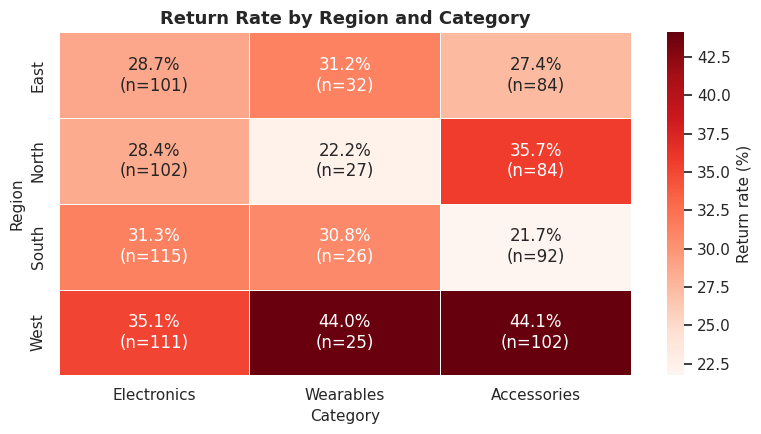

In [ ]:
# Region x category return-rate heatmap (diagnostic: is West high across all categories?)
rk = kn.groupby(["region", "category"]).agg(returned=("is_returned", "sum"), n=("is_returned", "size"))
rk["rate"] = rk["returned"] / rk["n"] * 100
rate_tbl = rk["rate"].unstack().loc[REGION_ORDER, cat.index]
n_tbl = rk["n"].unstack().loc[REGION_ORDER, cat.index]
annot = rate_tbl.round(1).astype(str) + "%\n(n=" + n_tbl.astype(str) + ")"
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(rate_tbl, annot=annot, fmt="", cmap="Reds", linewidths=.5, cbar_kws={"label": "Return rate (%)"}, ax=ax)
ax.set(title="Return Rate by Region and Category", xlabel="Category", ylabel="Region")
save_fig("15_return_rate_region_category")
plt.show()

In [ ]:
w = reg_ret.index[0]; pr_hi, pr_lo = prod_ret.index[0], prod_ret.index[-1]
display(Markdown(f"""
**Insights – returns**
* **{w}** needs attention: it has the most returned orders (**{reg_ret.loc[w,'returned_orders']:.0f}**) and the highest return rate (**{reg_ret.loc[w,'return_rate_%']:.1f}%**) versus {reg_ret['return_rate_%'].iloc[-1]:.1f}% in {reg_ret.index[-1]}. The regional difference is statistically significant (p = {chi_reg[1]:.4f}), so it is unlikely to be chance.
* Returned orders by region: {', '.join(f"{r} {int(v)}" for r, v in reg_ret['returned_orders'].items())}.
* The elevated {w} return rate appears in every category (see heatmap), which suggests a regional cause (for example logistics, carrier or delivery quality) rather than one product. This dataset cannot confirm the cause, and some category cells are small (see n in the heatmap).
* **Product return rates are all in a narrow band**: {pr_hi} is highest ({prod_ret.loc[pr_hi,'return_rate_%']:.1f}%) and {pr_lo} lowest ({prod_ret.loc[pr_lo,'return_rate_%']:.1f}%), but this difference is **not statistically significant** (p = {chi_prod[1]:.2f}). Returns are a company-wide issue, not caused by one bad product.
* In money terms, returned orders hold **{kpi['returned_revenue']:,.0f}** of revenue (**{kpi['returned_revenue_pct']:.1f}%**). Because Laptops are expensive, {prod_ret['returned_revenue'].idxmax()} returns alone account for {prod_ret['returned_revenue'].max():,.0f}.
"""))


**Insights – returns**
* **West** needs attention: it has the most returned orders (**95**) and the highest return rate (**39.9%**) versus 27.5% in South. The regional difference is statistically significant (p = 0.0150), so it is unlikely to be chance.
* Returned orders by region: West 95, North 65, East 62, South 64.
* The elevated West return rate appears in every category (see heatmap), which suggests a regional cause (for example logistics, carrier or delivery quality) rather than one product. This dataset cannot confirm the cause, and some category cells are small (see n in the heatmap).
* **Product return rates are all in a narrow band**: Headphones is highest (34.5%) and Monitor lowest (30.2%), but this difference is **not statistically significant** (p = 0.99). Returns are a company-wide issue, not caused by one bad product.
* In money terms, returned orders hold **415,640** of revenue (**30.9%**). Because Laptops are expensive, Laptop returns alone account for 223,500.


## 22. Price vs Quantity Analysis  *(Q10)*
Question: do customers buy fewer units when the product price is higher? We measure the **strength and direction** of the relationship with Pearson (linear) and Spearman (rank) correlation. Correlation does **not** prove causation.

In [ ]:
pear = stats.pearsonr(df["unit_price"], df["quantity"])
spear = stats.spearmanr(df["unit_price"], df["quantity"])
log_pear = stats.pearsonr(np.log(df["unit_price"]), df["quantity"])

def strength(r):
    r = abs(r)
    return "negligible / no" if r < 0.1 else "weak" if r < 0.3 else "moderate" if r < 0.5 else "strong"

print(f"Pearson  r = {pear[0]:+.4f}  (p = {pear[1]:.3f})")
print(f"Spearman rho = {spear[0]:+.4f}  (p = {spear[1]:.3f})")
print(f"Pearson on log(price) r = {log_pear[0]:+.4f}  (p = {log_pear[1]:.3f})")
print(f"Interpretation: {strength(pear[0])} linear relationship")

pq = df.groupby("product_name").agg(unit_price=("unit_price", "first"), avg_qty_per_order=("quantity", "mean"), total_units=("quantity", "sum"))
pq = pq.sort_values("unit_price")
display(pq)

Pearson  r = +0.0044  (p = 0.890)
Spearman rho = -0.0104  (p = 0.742)
Pearson on log(price) r = -0.0075  (p = 0.812)
Interpretation: negligible / no linear relationship


,unit_price,avg_qty_per_order,total_units
product_name,,,
Mouse,30.00,2.94,400
Keyboard,50.00,3.16,458
Headphones,100.00,3.08,370
Smartwatch,200.00,3.04,371
Monitor,300.00,2.78,503
Smartphone,800.00,3.11,442
Laptop,"1,500.00",3.01,464


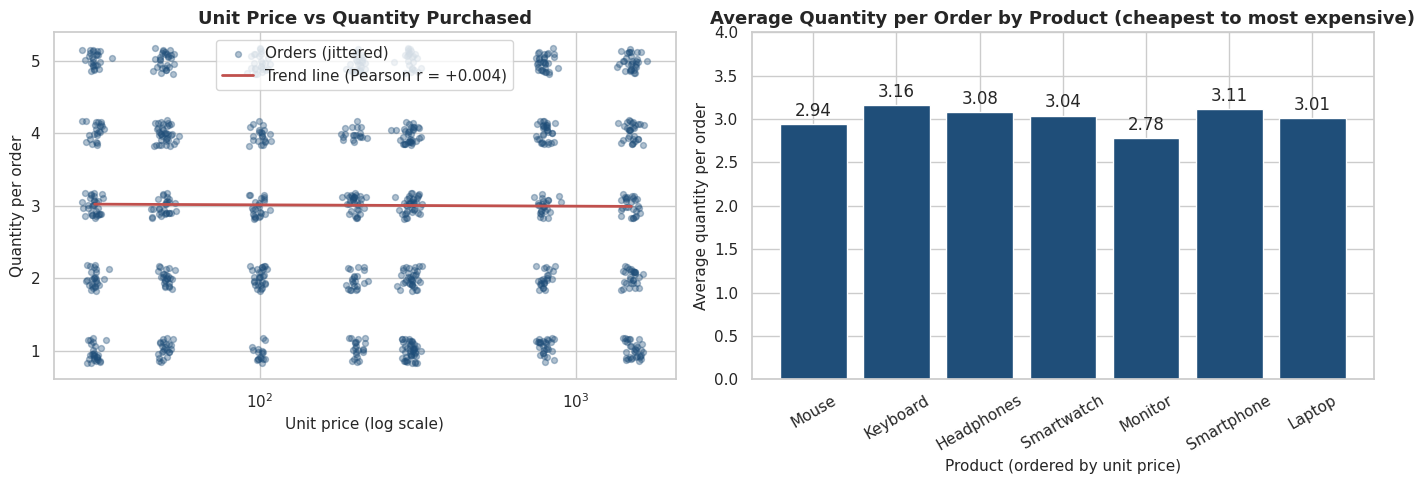

In [ ]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
jx = df["unit_price"] * np.exp(rng.normal(0, 0.04, len(df)))     # small horizontal jitter (log scale) so points do not overlap
jy = df["quantity"] + rng.uniform(-0.18, 0.18, len(df))
axes[0].scatter(jx, jy, alpha=0.35, s=18, color=MAIN, label="Orders (jittered)")
slope, intercept = np.polyfit(np.log(df["unit_price"]), df["quantity"], 1)
xs = np.linspace(df["unit_price"].min(), df["unit_price"].max(), 100)
axes[0].plot(xs, slope * np.log(xs) + intercept, color=ACCENT, linewidth=2, label=f"Trend line (Pearson r = {pear[0]:+.3f})")
axes[0].set_xscale("log")
axes[0].set(title="Unit Price vs Quantity Purchased", xlabel="Unit price (log scale)", ylabel="Quantity per order")
axes[0].legend()

bars = axes[1].bar(pq.index, pq["avg_qty_per_order"], color=MAIN)
axes[1].bar_label(bars, labels=[f"{v:.2f}" for v in pq["avg_qty_per_order"]], padding=3)
axes[1].set(title="Average Quantity per Order by Product (cheapest to most expensive)", xlabel="Product (ordered by unit price)", ylabel="Average quantity per order")
axes[1].tick_params(axis="x", rotation=30); axes[1].set_ylim(0, 4)
save_fig("16_price_vs_quantity")
plt.show()

In [ ]:
display(Markdown(f"""
**Insights – price vs quantity**
* Pearson r = **{pear[0]:+.3f}** (p = {pear[1]:.2f}) and Spearman rho = {spear[0]:+.3f} (p = {spear[1]:.2f}): a **{strength(pear[0])} relationship**, not statistically significant.
* The cheapest product ({pq.index[0]}, price {pq['unit_price'].iloc[0]:,.0f}) averages {pq['avg_qty_per_order'].iloc[0]:.2f} units per order and the most expensive ({pq.index[-1]}, price {pq['unit_price'].iloc[-1]:,.0f}) averages {pq['avg_qty_per_order'].iloc[-1]:.2f} – nearly the same.
* In this data, customers order about the same number of units (1–5) whatever the price. Because revenue = price × quantity, **price level (not quantity) drives revenue differences between products**.
* This is a statistical association only; it does not show that price has or has not *caused* buying behaviour.
"""))


**Insights – price vs quantity**
* Pearson r = **+0.004** (p = 0.89) and Spearman rho = -0.010 (p = 0.74): a **negligible / no relationship**, not statistically significant.
* The cheapest product (Mouse, price 30) averages 2.94 units per order and the most expensive (Laptop, price 1,500) averages 3.01 – nearly the same.
* In this data, customers order about the same number of units (1–5) whatever the price. Because revenue = price × quantity, **price level (not quantity) drives revenue differences between products**.
* This is a statistical association only; it does not show that price has or has not *caused* buying behaviour.


## 23. Customer Value Analysis  *(Q11)*

In [ ]:
total_rev = cust["revenue"].sum()
top10 = cust.head(10).copy()
top10["revenue_share_%"] = top10["revenue"] / total_rev * 100
display(top10[["revenue", "revenue_share_%", "orders", "quantity", "avg_order_value", "returned_orders"]])

cust["cum_share_%"] = cust["revenue"].cumsum() / total_rev * 100
cust["customer_rank_%"] = np.arange(1, len(cust) + 1) / len(cust) * 100
share_top10pct = cust.loc[cust["customer_rank_%"] <= 10, "revenue"].sum() / total_rev * 100
share_top20pct = cust.loc[cust["customer_rank_%"] <= 20, "revenue"].sum() / total_rev * 100

# customer value tiers
cust["tier"] = np.where(cust["customer_rank_%"] <= 10, "High value (top 10%)",
                np.where(cust["customer_rank_%"] <= 50, "Mid value (next 40%)", "Low value (bottom 50%)"))
tiers = cust.groupby("tier").agg(customers=("revenue", "size"), revenue=("revenue", "sum"), avg_orders=("orders", "mean"),
                                 avg_revenue=("revenue", "mean"), returned_orders=("returned_orders", "sum"), recorded=("recorded", "sum"))
tiers["revenue_share_%"] = tiers["revenue"] / total_rev * 100
tiers["return_rate_%"] = tiers["returned_orders"] / tiers["recorded"] * 100
tiers = tiers.loc[["High value (top 10%)", "Mid value (next 40%)", "Low value (bottom 50%)"]]
display(tiers[["customers", "revenue", "revenue_share_%", "avg_orders", "avg_revenue", "return_rate_%"]])

,revenue,revenue_share_%,orders,quantity,avg_order_value,returned_orders
customer_id,,,,,,
CUST0204,29100,2.16,9,33,"3,233.33",4
CUST0095,22440,1.67,9,34,"2,493.33",2
CUST0131,21180,1.57,8,24,"2,647.50",0
CUST0139,18350,1.36,7,22,"2,621.43",2
CUST0281,17850,1.33,8,25,"2,231.25",2
CUST0144,17320,1.29,5,22,"3,464.00",2
CUST0200,16700,1.24,4,13,"4,175.00",3
CUST0197,16150,1.20,5,18,"3,230.00",0
CUST0064,14600,1.08,7,17,"2,085.71",5


,customers,revenue,revenue_share_%,avg_orders,avg_revenue,return_rate_%
tier,,,,,,
High value (top 10%),29,402100,29.86,5.66,"13,865.52",31.01
Mid value (next 40%),117,733630,54.48,3.99,"6,270.34",33.48
Low value (bottom 50%),146,210870,15.66,2.53,"1,444.32",31.71


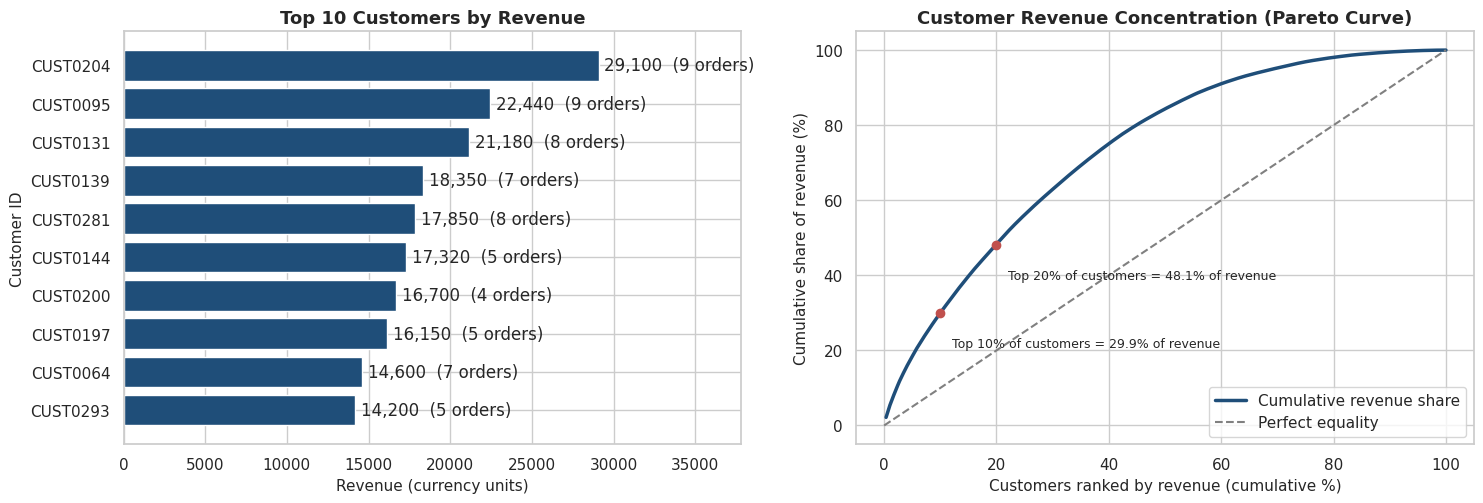

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
t = top10.sort_values("revenue")
bars = axes[0].barh(t.index, t["revenue"], color=MAIN)
axes[0].bar_label(bars, labels=[f"{v:,.0f}  ({int(o)} orders)" for v, o in zip(t["revenue"], t["orders"])], padding=4)
axes[0].set(title="Top 10 Customers by Revenue", xlabel="Revenue (currency units)", ylabel="Customer ID")
axes[0].set_xlim(0, t["revenue"].max() * 1.3)

axes[1].plot(cust["customer_rank_%"], cust["cum_share_%"], color=MAIN, linewidth=2.5, label="Cumulative revenue share")
axes[1].plot([0, 100], [0, 100], color="grey", linestyle="--", label="Perfect equality")
axes[1].scatter([10, 20], [share_top10pct, share_top20pct], color=ACCENT, zorder=5)
axes[1].text(12, share_top10pct - 9, f"Top 10% of customers = {share_top10pct:.1f}% of revenue", fontsize=9)
axes[1].text(22, share_top20pct - 9, f"Top 20% of customers = {share_top20pct:.1f}% of revenue", fontsize=9)
axes[1].set(title="Customer Revenue Concentration (Pareto Curve)", xlabel="Customers ranked by revenue (cumulative %)", ylabel="Cumulative share of revenue (%)")
axes[1].legend(loc="lower right")
save_fig("17_top_customers_pareto")
plt.show()

In [ ]:
c1 = cust.iloc[0]
hv = tiers.loc["High value (top 10%)"]
display(Markdown(f"""
**Insights – customer value**
* The top customer is **{cust.index[0]}** with **{c1['revenue']:,.0f}** revenue from {int(c1['orders'])} orders ({c1['revenue']/total_rev*100:.1f}% of all revenue).
* The **top 10% of customers ({int(hv['customers'])} customers) contribute {share_top10pct:.1f}%** of revenue and the top 20% contribute {share_top20pct:.1f}%. Revenue is moderately concentrated: valuable, but not dependent on a single customer.
* High-value customers place **{hv['avg_orders']:.1f} orders on average** versus {tiers.loc['Low value (bottom 50%)','avg_orders']:.1f} for the bottom half, so value is driven by **frequency and by buying high-priced products**.
* The average customer places {cust['orders'].mean():.1f} orders and spends {cust['revenue'].mean():,.0f}; {repeat:.1f}% of customers are repeat buyers, so retention matters.
* The return rate of high-value customers is {hv['return_rate_%']:.1f}% (all customers: {kpi['return_rate']:.1f}%): returns also hit the most valuable accounts.
"""))


**Insights – customer value**
* The top customer is **CUST0204** with **29,100** revenue from 9 orders (2.2% of all revenue).
* The **top 10% of customers (29 customers) contribute 29.9%** of revenue and the top 20% contribute 48.1%. Revenue is moderately concentrated: valuable, but not dependent on a single customer.
* High-value customers place **5.7 orders on average** versus 2.5 for the bottom half, so value is driven by **frequency and by buying high-priced products**.
* The average customer places 3.4 orders and spends 4,612; 86.0% of customers are repeat buyers, so retention matters.
* The return rate of high-value customers is 31.0% (all customers: 32.4%): returns also hit the most valuable accounts.


## 24. Business Questions and Answers
Each answer below is generated directly from the cleaned data (the numbers are calculated, not typed in), so they always match the analysis above.

In [ ]:
display(Markdown("### Q1. Which products and categories generate the highest sales?"))
display(prod[["revenue", "revenue_share_%", "orders", "quantity"]].rename(columns={"revenue_share_%": "share_%"}))
display(Markdown(f"""
**Answer:** **{prod.index[0]}** ({prod.iloc[0]['revenue']:,.0f}; {prod.iloc[0]['revenue_share_%']:.1f}%) and **{prod.index[1]}** ({prod.iloc[1]['revenue']:,.0f}; {prod.iloc[1]['revenue_share_%']:.1f}%) are the top products. The bottom product is **{prod.index[-1]}** ({prod.iloc[-1]['revenue']:,.0f}; {prod.iloc[-1]['revenue_share_%']:.1f}%).
The best category is **{cat.index[0]}** with {cat.iloc[0]['revenue']:,.0f} ({cat.iloc[0]['revenue_share_%']:.1f}% of revenue); {cat.index[1]} is second ({cat.iloc[1]['revenue_share_%']:.1f}%) and {cat.index[2]} third ({cat.iloc[2]['revenue_share_%']:.1f}%).
"""))

### Q1. Which products and categories generate the highest sales?

,revenue,share_%,orders,quantity
product_name,,,,
Laptop,696000,51.69,154,464
Smartphone,353600,26.26,142,442
Monitor,150900,11.21,181,503
Smartwatch,74200,5.51,122,371
Headphones,37000,2.75,120,370
Keyboard,22900,1.70,145,458
Mouse,12000,0.89,136,400



**Answer:** **Laptop** (696,000; 51.7%) and **Smartphone** (353,600; 26.3%) are the top products. The bottom product is **Mouse** (12,000; 0.9%).
The best category is **Electronics** with 1,200,500 (89.2% of revenue); Wearables is second (5.5%) and Accessories third (5.3%).


In [ ]:
display(Markdown("### Q2. Which regions contribute the most revenue?"))
display(reg[["revenue", "revenue_share_%", "orders", "avg_order_value"]])
display(Markdown(f"""
**Answer:** **{reg.index[0]}** contributes the most revenue ({reg.iloc[0]['revenue']:,.0f}; {reg.iloc[0]['revenue_share_%']:.1f}%) and **{reg.index[-1]}** the least ({reg.iloc[-1]['revenue']:,.0f}; {reg.iloc[-1]['revenue_share_%']:.1f}%). The gap is only {gap:.1f}%, so no region is dramatically ahead. ({reg_all.loc['Unknown','orders']} orders with an unknown region are excluded from the ranking.)
"""))

### Q2. Which regions contribute the most revenue?

,revenue,revenue_share_%,orders,avg_order_value
region,,,,
East,329950,24.50,231,"1,428.35"
North,324990,24.13,229,"1,419.17"
West,323390,24.02,246,"1,314.59"
South,301040,22.36,244,"1,233.77"



**Answer:** **East** contributes the most revenue (329,950; 24.5%) and **South** the least (301,040; 22.4%). The gap is only 9.6%, so no region is dramatically ahead. (50 orders with an unknown region are excluded from the ranking.)


In [ ]:
display(Markdown("### Q3. Which products have the highest quantity sold?"))
display(prod.sort_values("quantity", ascending=False)[["quantity", "quantity_share_%", "revenue", "revenue_share_%"]])
qs = prod.sort_values("quantity", ascending=False)
display(Markdown(f"""
**Answer:** **{qs.index[0]}** ({int(qs.iloc[0]['quantity'])} units), then **{qs.index[1]}** ({int(qs.iloc[1]['quantity'])}) and **{qs.index[2]}** ({int(qs.iloc[2]['quantity'])}). Compared with revenue, the picture is very different: Monitor leads in units but {prod.index[0]} leads in revenue with only {prod.loc[prod.index[0],'quantity']} units, because of its much higher price.
"""))

### Q3. Which products have the highest quantity sold?

,quantity,quantity_share_%,revenue,revenue_share_%
product_name,,,,
Monitor,503,16.72,150900,11.21
Laptop,464,15.43,696000,51.69
Keyboard,458,15.23,22900,1.70
Smartphone,442,14.69,353600,26.26
Mouse,400,13.30,12000,0.89
Smartwatch,371,12.33,74200,5.51
Headphones,370,12.30,37000,2.75



**Answer:** **Monitor** (503 units), then **Laptop** (464) and **Keyboard** (458). Compared with revenue, the picture is very different: Monitor leads in units but Laptop leads in revenue with only 464 units, because of its much higher price.


In [ ]:
display(Markdown("### Q4. How do sales change month by month?"))
display(mon[["revenue", "orders", "quantity", "revenue_MoM_%"]])
display(Markdown(f"""
**Answer:** Among complete months, revenue peaked in **{full['revenue'].idxmax()}** ({full['revenue'].max():,.0f}) and was lowest in **{full['revenue'].idxmin()}** ({full['revenue'].min():,.0f}). Orders peaked in {full['orders'].idxmax()} ({full['orders'].max()}) and were lowest in {full['orders'].idxmin()} ({full['orders'].min()}). Sales are uneven rather than steadily growing; {', '.join(partial_months)} contains only a few days of data and is not compared.
"""))

### Q4. How do sales change month by month?

,revenue,orders,quantity,revenue_MoM_%
order_month,,,,
Jan 2023,141360,94,298,NaN
Feb 2023,78910,74,201,-44.18
Mar 2023,67660,67,210,-14.26
Apr 2023,87840,66,189,29.83
May 2023,120080,86,267,36.70
Jun 2023,129450,90,274,7.80
Jul 2023,103160,79,226,-20.31
Aug 2023,108050,84,239,4.74
Sep 2023,119490,81,240,10.59



**Answer:** Among complete months, revenue peaked in **Nov 2023** (147,150) and was lowest in **Mar 2023** (67,660). Orders peaked in Jan 2023 (94) and were lowest in Apr 2023 (66). Sales are uneven rather than steadily growing; Jan 2024 contains only a few days of data and is not compared.


In [ ]:
display(Markdown("### Q5. Which age groups and genders contribute most to sales?"))
display(a[["customers", "revenue", "revenue_share_%", "orders", "quantity", "avg_order_value"]])
display(gen[["revenue", "revenue_share_%", "orders", "quantity", "avg_order_value"]])
display(Markdown(f"""
**Answer:** The **{ag_top}** age group contributes the most ({a.loc[ag_top,'revenue_share_%']:.1f}% of revenue, {a.loc[ag_top,'orders']} orders, {a.loc[ag_top,'quantity']:,} units), and **{ag_low}** the least ({a.loc[ag_low,'revenue_share_%']:.1f}%). By gender, **{gl}** orders contribute {gen.loc[gl,'revenue_share_%']:.1f}% and {gs} {gen.loc[gs,'revenue_share_%']:.1f}% – a small difference.
"""))

### Q5. Which age groups and genders contribute most to sales?

,customers,revenue,revenue_share_%,orders,quantity,avg_order_value
age_group,,,,,,
18-25,37,126580,9.40,107,322,"1,182.99"
26-35,46,180780,13.42,150,430,"1,205.20"
36-45,56,246840,18.33,191,575,"1,292.36"
46-55,54,295370,21.93,206,641,"1,433.83"
56+,94,482370,35.82,339,1022,"1,422.92"


,revenue,revenue_share_%,orders,quantity,avg_order_value
gender,,,,,
Male,715590,53.14,524,1586,"1,365.63"
Female,631010,46.86,476,1422,"1,325.65"



**Answer:** The **56+** age group contributes the most (35.8% of revenue, 339 orders, 1,022 units), and **18-25** the least (9.4%). By gender, **Male** orders contribute 53.1% and Female 46.9% – a small difference.


In [ ]:
display(Markdown("### Q6. Which regions have the highest returned orders?"))
display(reg_ret[["returned_orders", "recorded_status", "return_rate_%", "returned_revenue"]])
display(Markdown(f"""
**Answer:** **{reg_ret.index[0]}** has the most returned orders (**{reg_ret.iloc[0]['returned_orders']:.0f}**) and the highest return rate (**{reg_ret.iloc[0]['return_rate_%']:.1f}%**). The lowest is **{reg_ret.index[-1]}** ({reg_ret.iloc[-1]['return_rate_%']:.1f}%). The difference between regions is statistically significant (chi-square p = {chi_reg[1]:.4f}), so **{reg_ret.index[0]} requires attention**.
"""))

### Q6. Which regions have the highest returned orders?

,returned_orders,recorded_status,return_rate_%,returned_revenue
region,,,,
West,95,238,39.92,108710
North,65,213,30.52,81170
East,62,217,28.57,101680
South,64,233,27.47,88900



**Answer:** **West** has the most returned orders (**95**) and the highest return rate (**39.9%**). The lowest is **South** (27.5%). The difference between regions is statistically significant (chi-square p = 0.0150), so **West requires attention**.


In [ ]:
display(Markdown("### Q7. What percentage of orders are Delivered, In Transit, or Returned?"))
display(ship[["orders", "% of all orders", "% of recorded-status orders"]])
display(Markdown(f"""
**Answer (on the {rec} orders with a recorded status):** **Delivered {sp['Delivered']:.1f}%**, **In Transit {sp['In Transit']:.1f}%**, **Returned {sp['Returned']:.1f}%**. (Including the {ship.loc['Unknown','orders']} unknown-status orders in the base: Delivered {ship.loc['Delivered','% of all orders']:.1f}%, In Transit {ship.loc['In Transit','% of all orders']:.1f}%, Returned {ship.loc['Returned','% of all orders']:.1f}%, Unknown {ship.loc['Unknown','% of all orders']:.1f}%.)
"""))

### Q7. What percentage of orders are Delivered, In Transit, or Returned?

,orders,% of all orders,% of recorded-status orders
shipping_status,,,
Delivered,313,31.30,32.95
In Transit,329,32.90,34.63
Returned,308,30.80,32.42
Unknown,50,5.00,NaN



**Answer (on the 950 orders with a recorded status):** **Delivered 32.9%**, **In Transit 34.6%**, **Returned 32.4%**. (Including the 50 unknown-status orders in the base: Delivered 31.3%, In Transit 32.9%, Returned 30.8%, Unknown 5.0%.)


In [ ]:
display(Markdown("### Q8. Which products have the highest return rate?"))
display(prod_ret[["recorded_status", "returned_orders", "return_rate_%"]])
display(Markdown(f"""
**Answer:** Every product has at least {int(prod_ret['recorded_status'].min())} recorded orders (rule: minimum {MIN_ORDERS}), so all {len(prod_ret)} are ranked. **{prod_ret.index[0]}** has the highest return rate (**{prod_ret.iloc[0]['return_rate_%']:.1f}%**), followed by {prod_ret.index[1]} ({prod_ret.iloc[1]['return_rate_%']:.1f}%) and {prod_ret.index[2]} ({prod_ret.iloc[2]['return_rate_%']:.1f}%); the lowest is {prod_ret.index[-1]} ({prod_ret.iloc[-1]['return_rate_%']:.1f}%). However, the chi-square test (p = {chi_prod[1]:.2f}) shows the differences between products are **not statistically significant**, so returns are not concentrated in one product.
"""))

### Q8. Which products have the highest return rate?

,recorded_status,returned_orders,return_rate_%
product_name,,,
Headphones,116,40,34.48
Laptop,144,49,34.03
Mouse,131,44,33.59
Smartwatch,117,38,32.48
Smartphone,133,42,31.58
Keyboard,137,43,31.39
Monitor,172,52,30.23



**Answer:** Every product has at least 116 recorded orders (rule: minimum 30), so all 7 are ranked. **Headphones** has the highest return rate (**34.5%**), followed by Laptop (34.0%) and Mouse (33.6%); the lowest is Monitor (30.2%). However, the chi-square test (p = 0.99) shows the differences between products are **not statistically significant**, so returns are not concentrated in one product.


In [ ]:
display(Markdown("### Q9. How much revenue is generated from each category and region?"))
display(cr)
display(Markdown(f"""
**Answer:** The table above gives revenue for every category-region combination (total {cr.loc['Total','Total']:,.0f}). By category: {', '.join(f"{c} {cr.loc[c,'Total']:,.0f}" for c in cat.index)}. By region: {', '.join(f"{r} {cr.loc['Total',r]:,.0f}" for r in REGION_ORDER)}, Unknown {cr.loc['Total','Unknown']:,.0f}. The largest combination is **{cr.drop(index='Total',columns=['Total','Unknown']).stack().idxmax()[0]} in {cr.drop(index='Total',columns=['Total','Unknown']).stack().idxmax()[1]}** ({cr.drop(index='Total',columns=['Total','Unknown']).stack().max():,.0f}).
"""))

### Q9. How much revenue is generated from each category and region?

region,East,North,South,West,Unknown,Total
category,,,,,,
Electronics,288900,294500,266600,289700,60800,1200500
Wearables,23800,14000,17800,15200,3400,74200
Accessories,17250,16490,16640,18490,3030,71900
Total,329950,324990,301040,323390,67230,1346600



**Answer:** The table above gives revenue for every category-region combination (total 1,346,600). By category: Electronics 1,200,500, Wearables 74,200, Accessories 71,900. By region: East 329,950, North 324,990, South 301,040, West 323,390, Unknown 67,230. The largest combination is **Electronics in North** (294,500).


In [ ]:
display(Markdown("### Q10. Is there a relationship between product price and quantity purchased?"))
display(Markdown(f"""
**Answer:** **No meaningful relationship.** Pearson r = {pear[0]:+.3f} (p = {pear[1]:.2f}), Spearman rho = {spear[0]:+.3f} (p = {spear[1]:.2f}). The coefficient is practically zero, so quantity does not rise or fall with price: it is a **{strength(pear[0])}** relationship. This is a correlation only and does not prove or disprove that price affects demand.
"""))

### Q10. Is there a relationship between product price and quantity purchased?


**Answer:** **No meaningful relationship.** Pearson r = +0.004 (p = 0.89), Spearman rho = -0.010 (p = 0.74). The coefficient is practically zero, so quantity does not rise or fall with price: it is a **negligible / no** relationship. This is a correlation only and does not prove or disprove that price affects demand.


In [ ]:
display(Markdown("### Q11. Which customers contribute the most to total sales?"))
display(top10[["revenue", "revenue_share_%", "orders", "quantity", "avg_order_value"]])
display(Markdown(f"""
**Answer:** The top customers are {', '.join(f"**{i}** ({r:,.0f})" for i, r in top10['revenue'].head(5).items())}. The top 10 customers together bring {top10['revenue'].sum():,.0f} ({top10['revenue'].sum()/total_rev*100:.1f}% of revenue); the top 10% of all customers bring **{share_top10pct:.1f}%**. These high-value customers are important because they buy more often ({hv['avg_orders']:.1f} orders vs {cust['orders'].mean():.1f} on average) and buy higher-priced products, so losing or disappointing them has an outsized effect on revenue.
"""))

### Q11. Which customers contribute the most to total sales?

,revenue,revenue_share_%,orders,quantity,avg_order_value
customer_id,,,,,
CUST0204,29100,2.16,9,33,"3,233.33"
CUST0095,22440,1.67,9,34,"2,493.33"
CUST0131,21180,1.57,8,24,"2,647.50"
CUST0139,18350,1.36,7,22,"2,621.43"
CUST0281,17850,1.33,8,25,"2,231.25"
CUST0144,17320,1.29,5,22,"3,464.00"
CUST0200,16700,1.24,4,13,"4,175.00"
CUST0197,16150,1.20,5,18,"3,230.00"
CUST0064,14600,1.08,7,17,"2,085.71"



**Answer:** The top customers are **CUST0204** (29,100), **CUST0095** (22,440), **CUST0131** (21,180), **CUST0139** (18,350), **CUST0281** (17,850). The top 10 customers together bring 187,890 (14.0% of revenue); the top 10% of all customers bring **29.9%**. These high-value customers are important because they buy more often (5.7 orders vs 3.4 on average) and buy higher-priced products, so losing or disappointing them has an outsized effect on revenue.


In [ ]:
display(Markdown("### Q12. What recommendations can be given to improve sales and shipping performance?"))
display(Markdown("See **Section 26 – Business Recommendations** below, each recommendation is tied to evidence from Q1–Q11."))

### Q12. What recommendations can be given to improve sales and shipping performance?

See **Section 26 – Business Recommendations** below, each recommendation is tied to evidence from Q1–Q11.

## 25. Key Findings

In [ ]:
wk = full["revenue"].nsmallest(3).index.tolist()
display(Markdown(f"""
1. **Revenue** totals **{kpi['total_revenue']:,.0f}** from {kpi['total_orders']:,} orders and {kpi['total_quantity']:,} units; average order value is {kpi['avg_order_value']:,.0f}.
2. **Revenue is concentrated in a few high-priced products**: {prod.index[0]} ({prod.iloc[0]['revenue_share_%']:.1f}%) and {prod.index[1]} ({prod.iloc[1]['revenue_share_%']:.1f}%). **{cat.index[0]}** gives {cat.iloc[0]['revenue_share_%']:.1f}% of revenue.
3. **Volume ≠ value:** {qs.index[0]} sells the most units ({int(qs.iloc[0]['quantity'])}) but ranks {list(prod.index).index(qs.index[0])+1} in revenue; Accessories are {cat.loc['Accessories','orders']/len(df)*100:.0f}% of orders but only {cat.loc['Accessories','revenue_share_%']:.1f}% of revenue.
4. **Regions are balanced in revenue** ({reg.index[0]} highest, {reg.index[-1]} lowest, gap {gap:.1f}%).
5. **Sales are uneven by month:** peak {full['revenue'].idxmax()} ({full['revenue'].max():,.0f}), low {full['revenue'].idxmin()} ({full['revenue'].min():,.0f}); weakest months: {', '.join(wk)}.
6. **Older customers drive sales:** age 46+ gives {a.loc[['46-55','56+'],'revenue_share_%'].sum():.1f}% of revenue; {ag_top} alone gives {a.loc[ag_top,'revenue_share_%']:.1f}%. Gender split is {gen.loc['Male','revenue_share_%']:.1f}% male / {gen.loc['Female','revenue_share_%']:.1f}% female.
7. **Only {sp['Delivered']:.1f}% of orders are Delivered**; {sp['In Transit']:.1f}% are In Transit and **{sp['Returned']:.1f}% are Returned** (recorded-status orders).
8. **Returned orders hold {kpi['returned_revenue']:,.0f} of revenue ({kpi['returned_revenue_pct']:.1f}%)**; net revenue after returns is {kpi['net_revenue']:,.0f}.
9. **{reg_ret.index[0]} has the highest return rate ({reg_ret.iloc[0]['return_rate_%']:.1f}%) and most returns ({reg_ret.iloc[0]['returned_orders']:.0f})** – statistically significant (p = {chi_reg[1]:.4f}). Product-level return differences are not significant (p = {chi_prod[1]:.2f}).
10. **Price and quantity are unrelated** (r = {pear[0]:+.3f}); products differ in revenue because of price, not quantity.
11. **Top 10% of customers bring {share_top10pct:.1f}% of revenue**; the top customer is {cust.index[0]} ({cust.iloc[0]['revenue']:,.0f}). {repeat:.0f}% of customers are repeat buyers.
12. **Shipping fees weigh {fee.loc['Accessories','fee_as_%_of_order_value']:.1f}% of Accessories order value** versus {fee.loc['Electronics','fee_as_%_of_order_value']:.1f}% for Electronics.
13. **Data-quality issues** found and fixed or documented: {int(df['unit_price_corrected'].sum())} wrong unit prices, {raw_df['Age'].isna().sum()} missing ages (only {missing_after} unrecoverable), {reg_missing} missing regions, {ship_missing} missing shipping statuses, and customer IDs carrying inconsistent gender/region.
"""))


1. **Revenue** totals **1,346,600** from 1,000 orders and 3,008 units; average order value is 1,347.
2. **Revenue is concentrated in a few high-priced products**: Laptop (51.7%) and Smartphone (26.3%). **Electronics** gives 89.2% of revenue.
3. **Volume ≠ value:** Monitor sells the most units (503) but ranks 3 in revenue; Accessories are 40% of orders but only 5.3% of revenue.
4. **Regions are balanced in revenue** (East highest, South lowest, gap 9.6%).
5. **Sales are uneven by month:** peak Nov 2023 (147,150), low Mar 2023 (67,660); weakest months: Mar 2023, Feb 2023, Apr 2023.
6. **Older customers drive sales:** age 46+ gives 57.8% of revenue; 56+ alone gives 35.8%. Gender split is 53.1% male / 46.9% female.
7. **Only 32.9% of orders are Delivered**; 34.6% are In Transit and **32.4% are Returned** (recorded-status orders).
8. **Returned orders hold 415,640 of revenue (30.9%)**; net revenue after returns is 930,960.
9. **West has the highest return rate (39.9%) and most returns (95)** – statistically significant (p = 0.0150). Product-level return differences are not significant (p = 0.99).
10. **Price and quantity are unrelated** (r = +0.004); products differ in revenue because of price, not quantity.
11. **Top 10% of customers bring 29.9% of revenue**; the top customer is CUST0204 (29,100). 86% of customers are repeat buyers.
12. **Shipping fees weigh 6.8% of Accessories order value** versus 0.5% for Electronics.
13. **Data-quality issues** found and fixed or documented: 20 wrong unit prices, 100 missing ages (only 7 unrecoverable), 50 missing regions, 50 missing shipping statuses, and customer IDs carrying inconsistent gender/region.


## 26. Business Recommendations
Every recommendation below refers to evidence found in this dataset.

In [ ]:
single = int((cust["orders"] == 1).sum())
display(Markdown(f"""
### 1. Sales growth
* **Protect and grow the two revenue engines.** {prod.index[0]} and {prod.index[1]} generate {prod['revenue_share_%'].iloc[:2].sum():.1f}% of revenue from {prod['orders'].iloc[:2].sum()/len(df)*100:.0f}% of orders. Keep them always in stock and feature them in campaigns.
* **Lift low months.** Revenue in {wk[0]} was only {full.loc[wk[0],'revenue']:,.0f} against a monthly average of {full['revenue'].mean():,.0f}. Plan promotions, bundles or email campaigns for {', '.join(wk)}, the three weakest months.
* **Raise order value by cross-selling.** Accessories form {cat.loc['Accessories','orders']/len(df)*100:.0f}% of orders but have an average order value of only {cat.loc['Accessories','avg_order_value']:,.0f}; offering accessory bundles with every Laptop, Smartphone and Monitor order can increase basket size.

### 2. Product strategy
* **Do not rely on price cuts to sell more units.** Price and quantity are unrelated (r = {pear[0]:+.3f}), so discounting is not expected to lift units on its own; test any discount on a small scale first.
* **Review the lowest earners.** {prod.index[-1]} and {prod.index[-2]} give {prod.loc[[prod.index[-1], prod.index[-2]],'revenue_share_%'].sum():.1f}% of revenue combined; keep them as add-ons/bundle items rather than standalone stock priorities.
* **Develop the Wearables line.** Wearables (Smartwatch only) give {cat.loc['Wearables','revenue_share_%']:.1f}% of revenue from {cat.loc['Wearables','orders']} orders; trial additional wearables or Smartphone + Smartwatch bundles.

### 3. Regional strategy
* **{reg.index[0]}** is the strongest region ({reg.iloc[0]['revenue_share_%']:.1f}% of revenue, highest order value) – use it as the best-practice benchmark.
* **{reg.index[-1]}** has the lowest revenue and the lowest average order value ({reg.loc[reg.index[-1],'avg_order_value']:,.0f}) but a low return rate ({reg.loc[reg.index[-1],'return_rate_%']:.1f}%) – it is a healthy growth opportunity; push higher-value Electronics there.
* **Fix {reg_ret.index[0]} fulfilment first** (see return and shipping recommendations): it has strong volume ({reg.loc[reg_ret.index[0],'orders']} orders) but the highest return rate.

### 4. Customer retention
* **Create a VIP / loyalty programme for the top 10% of customers** ({int(hv['customers'])} customers, {share_top10pct:.1f}% of revenue): priority shipping, early access, dedicated support.
* **Convert one-time buyers.** {single} customers ({single/len(cust)*100:.0f}%) ordered only once; send follow-up offers after the first purchase.
* **Protect high-value customers from bad experiences.** Their return rate is {hv['return_rate_%']:.1f}%; flag any VIP order that is returned and follow up personally.

### 5. Marketing and customer segmentation
* **Prioritise the 46+ segment** ({a.loc[['46-55','56+'],'revenue_share_%'].sum():.1f}% of revenue; {ag_top} alone {a.loc[ag_top,'revenue_share_%']:.1f}%) with Electronics-focused campaigns and trust messages (warranty, easy returns).
* **Grow the 18-25 group**, the smallest ({a.loc['18-25','revenue_share_%']:.1f}% of revenue), with entry-level products (Accessories, Smartwatch) and student offers.
* **Gender-neutral marketing is appropriate**: the male/female revenue split is {gen.loc['Male','revenue_share_%']:.1f}% / {gen.loc['Female','revenue_share_%']:.1f}%.

### 6. Return reduction
* **Treat returns as the number-one business problem:** the return rate is {kpi['return_rate']:.1f}% and returned orders hold {kpi['returned_revenue_pct']:.1f}% of revenue ({kpi['returned_revenue']:,.0f}).
* **Investigate {reg_ret.index[0]} region** (return rate {reg_ret.iloc[0]['return_rate_%']:.1f}% vs {reg_ret['return_rate_%'].iloc[-1]:.1f}% in {reg_ret.index[-1]}): audit carriers, packaging, delivery time and warehouse for that region.
* **Because every product has a similar return rate** (no significant product difference), focus on process fixes (order accuracy, packaging, product-description quality) rather than removing a single product.
* **Start recording a return reason** for each return – the current data cannot say why customers return products.
* Laptops give the biggest return loss ({prod_ret.loc['Laptop','returned_revenue']:,.0f}); add extra quality-check and packaging steps for high-value items.

### 7. Shipping improvement
* **Only {sp['Delivered']:.1f}% of recorded orders are Delivered** while {sp['In Transit']:.1f}% are still In Transit: track In-Transit ageing and set a delivery-time target with alerts.
* **Reduce the cost burden on cheap orders:** shipping equals {fee.loc['Accessories','fee_as_%_of_order_value']:.1f}% of Accessories order value; consider a free-shipping threshold or bundles to increase order value.
* **Fix the {ship.loc['Unknown','orders']} unknown-status and {reg_all.loc['Unknown','orders']} unknown-region records** by making these fields mandatory at order entry.
* **Add delivery date and delivery-time fields** so future analysis can measure real delivery speed (not available now).

### 8. Inventory and product planning
* **Plan stock around the demand pattern:** peak revenue month {full['revenue'].idxmax()} and strong {full['orders'].idxmax()} orders; keep high-priced items available before these peaks.
* **Plan units and value separately:** {', '.join(f"{p} ({int(qs.loc[p,'quantity'])} units)" for p in qs.index[:3])} sell the most units and need replenishment volume; {prod.index[0]} and {prod.index[1]} carry the most value per order and need capital and secure handling.
* **Collect more than one year of data** (the data covers {mon['full_month'].sum()} complete months) before making firm seasonal forecasts.
"""))


### 1. Sales growth
* **Protect and grow the two revenue engines.** Laptop and Smartphone generate 77.9% of revenue from 30% of orders. Keep them always in stock and feature them in campaigns.
* **Lift low months.** Revenue in Mar 2023 was only 67,660 against a monthly average of 111,268. Plan promotions, bundles or email campaigns for Mar 2023, Feb 2023, Apr 2023, the three weakest months.
* **Raise order value by cross-selling.** Accessories form 40% of orders but have an average order value of only 179; offering accessory bundles with every Laptop, Smartphone and Monitor order can increase basket size.

### 2. Product strategy
* **Do not rely on price cuts to sell more units.** Price and quantity are unrelated (r = +0.004), so discounting is not expected to lift units on its own; test any discount on a small scale first.
* **Review the lowest earners.** Mouse and Keyboard give 2.6% of revenue combined; keep them as add-ons/bundle items rather than standalone stock priorities.
* **Develop the Wearables line.** Wearables (Smartwatch only) give 5.5% of revenue from 122 orders; trial additional wearables or Smartphone + Smartwatch bundles.

### 3. Regional strategy
* **East** is the strongest region (24.5% of revenue, highest order value) – use it as the best-practice benchmark.
* **South** has the lowest revenue and the lowest average order value (1,234) but a low return rate (27.5%) – it is a healthy growth opportunity; push higher-value Electronics there.
* **Fix West fulfilment first** (see return and shipping recommendations): it has strong volume (246 orders) but the highest return rate.

### 4. Customer retention
* **Create a VIP / loyalty programme for the top 10% of customers** (29 customers, 29.9% of revenue): priority shipping, early access, dedicated support.
* **Convert one-time buyers.** 41 customers (14%) ordered only once; send follow-up offers after the first purchase.
* **Protect high-value customers from bad experiences.** Their return rate is 31.0%; flag any VIP order that is returned and follow up personally.

### 5. Marketing and customer segmentation
* **Prioritise the 46+ segment** (57.8% of revenue; 56+ alone 35.8%) with Electronics-focused campaigns and trust messages (warranty, easy returns).
* **Grow the 18-25 group**, the smallest (9.4% of revenue), with entry-level products (Accessories, Smartwatch) and student offers.
* **Gender-neutral marketing is appropriate**: the male/female revenue split is 53.1% / 46.9%.

### 6. Return reduction
* **Treat returns as the number-one business problem:** the return rate is 32.4% and returned orders hold 30.9% of revenue (415,640).
* **Investigate West region** (return rate 39.9% vs 27.5% in South): audit carriers, packaging, delivery time and warehouse for that region.
* **Because every product has a similar return rate** (no significant product difference), focus on process fixes (order accuracy, packaging, product-description quality) rather than removing a single product.
* **Start recording a return reason** for each return – the current data cannot say why customers return products.
* Laptops give the biggest return loss (223,500); add extra quality-check and packaging steps for high-value items.

### 7. Shipping improvement
* **Only 32.9% of recorded orders are Delivered** while 34.6% are still In Transit: track In-Transit ageing and set a delivery-time target with alerts.
* **Reduce the cost burden on cheap orders:** shipping equals 6.8% of Accessories order value; consider a free-shipping threshold or bundles to increase order value.
* **Fix the 50 unknown-status and 50 unknown-region records** by making these fields mandatory at order entry.
* **Add delivery date and delivery-time fields** so future analysis can measure real delivery speed (not available now).

### 8. Inventory and product planning
* **Plan stock around the demand pattern:** peak revenue month Nov 2023 and strong Jan 2023 orders; keep high-priced items available before these peaks.
* **Plan units and value separately:** Monitor (503 units), Laptop (464 units), Keyboard (458 units) sell the most units and need replenishment volume; Laptop and Smartphone carry the most value per order and need capital and secure handling.
* **Collect more than one year of data** (the data covers 12 complete months) before making firm seasonal forecasts.


## 27. Conclusion
The cleaned e-commerce dataset shows a business whose **revenue comes mainly from a small number of high-priced Electronics products (Laptop and Smartphone)**, spread fairly evenly across the four regions and led by customers aged 46 and above. Customer revenue is moderately concentrated in a group of high-value repeat buyers.

The most important weakness is **fulfilment**: roughly one in three recorded orders is returned and only about one in three is confirmed as delivered. The return problem is **regional (West) and company-wide** rather than caused by a single product. Price and quantity are unrelated, so growth should come from **order value, retention, cross-selling and fixing returns**, not from price cuts alone.

**Limitations:** one year of data (the last month has only 3 days), no order ID, no delivery dates or return reasons, 5–10% missing values in some fields, and customer IDs with inconsistent gender/region. These limit customer-level conclusions and should be fixed in the data-collection process.

*End of notebook.*